# PBMC 10k scRNA-seq analysis: Stage 1 (Seurat / R)

R + Seurat version of the Scanpy notebook `pbmc10k_analysis.ipynb`. It covers:

1. Loading the 10x Genomics filtered feature-barcode matrix
2. QC metrics (mitochondrial and ribosomal content, genes and UMIs per cell), doublet detection with scDblFinder, and QC filtering
3. Normalisation, highly variable genes (HVGs), PCA, neighbour graph, UMAP
4. Louvain clustering at two resolutions and marker genes per cluster
5. Marker-based cell type annotation with module scores

**All paths are relative to the project root** (the folder with `install.sh`; this notebook is in `scripts/seurat_analysis/` and finds the root itself):

| | Location |
|---|---|
| Input: 10x matrix | `data/pbmc10_data/` (`barcodes.tsv.gz`, `features.tsv.gz`, `matrix.mtx.gz`) |
| Output: Seurat objects | `data/*.rds` |
| Output: figures | `data/figures/` |
| Output: tables | `data/tables/` |

All results (figures, tables and `.rds` objects) are written only to `data/`. `data/` and the input data folder are listed in `.gitignore`, so neither is pushed to GitHub.

**Requirements:** R >= 4.3, Seurat >= 5.0, dplyr, tidyr, ggplot2, patchwork, scDblFinder and SingleCellExperiment (Bioconductor), and the Jupyter R kernel (IRkernel). In WSL2, running `bash install.sh` from the project root creates the `seurat_env` conda environment with all of these (R 4.4.3) and registers the **R 4.4.3 (seurat_env)** kernel this notebook uses.

### Scanpy to Seurat cheat-sheet

| Scanpy | Seurat / R |
|---|---|
| `AnnData` (`adata`) | `Seurat` object |
| `adata.obs` / `adata.var` | `obj@meta.data` / `obj[["RNA"]][[]]` |
| `n_genes_by_counts` | `nFeature_RNA` |
| `total_counts` | `nCount_RNA` |
| `pct_counts_mt` / `pct_counts_ribo` | `percent.mt` / `percent.ribo` |
| `sc.pp.scrublet` (doublet detection) | `scDblFinder::scDblFinder` (Bioconductor) |
| raw counts | `counts` layer |
| `normalize_total(target_sum=1e4)` + `log1p` | `NormalizeData(normalization.method = "LogNormalize", scale.factor = 1e4)` (`data` layer) |
| `highly_variable_genes(flavor='seurat_v3')` | `FindVariableFeatures(selection.method = "vst")` |
| `sc.pp.pca` | `ScaleData` + `RunPCA` |
| `sc.pp.neighbors` | `FindNeighbors` |
| `sc.tl.louvain` | `FindClusters(algorithm = 1)` |
| `sc.tl.umap` | `RunUMAP` |
| `sc.tl.rank_genes_groups` | `FindAllMarkers` |
| `sc.tl.score_genes` | `AddModuleScore` |
| `sc.pl.violin` / `sc.pl.umap` / `sc.pl.dotplot` | `VlnPlot` / `DimPlot` / `DotPlot` |
| `sc.write(...h5ad)` / `sc.read_h5ad` | `saveRDS(...rds)` / `readRDS` |

## Setup

In [1]:
# WSL2: `bash install.sh` installs everything (conda env seurat_env, kernel "R 4.4.3 (seurat_env)").
# Windows R: run once if the packages are missing:
# install.packages(c("Seurat", "dplyr", "tidyr", "ggplot2", "patchwork"))

suppressPackageStartupMessages({
  library(Seurat)
  library(Matrix)
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(patchwork)
})

set.seed(198716)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 120)  # inline plot size in Jupyter
packageVersion("Seurat")

[1] ‘5.5.1’

In [2]:
# ---- All paths are relative to the project root: the folder that holds install.sh and scripts/ ----
# Jupyter starts in the notebook's own folder (scripts/seurat_analysis/), so look upwards from there for the root.
find_project_root <- function(start = getwd()) {
  dir <- normalizePath(start, winslash = "/", mustWork = TRUE)
  repeat {
    if (file.exists(file.path(dir, "install.sh")) && dir.exists(file.path(dir, "scripts"))) return(dir)
    parent <- dirname(dir)
    if (parent == dir) stop("Project root (folder with install.sh and scripts/) not found above ", start)
    dir <- parent
  }
}
base_dir    <- find_project_root()
cat("Project root:", base_dir, "\n")
data_dir    <- file.path(base_dir, "data", "pbmc10_data")   # 10x input: barcodes / features / matrix (git-ignored)
results_dir <- file.path(base_dir, "data")   # every result goes here; data/ is git-ignored, never pushed to GitHub
fig_dir     <- file.path(results_dir, "figures")
table_dir   <- file.path(results_dir, "tables")

dir.create(fig_dir,   showWarnings = FALSE, recursive = TRUE)
dir.create(table_dir, showWarnings = FALSE, recursive = TRUE)

if (!dir.exists(data_dir)) stop("10x input folder not found: ", data_dir)

# Show a plot inline and save a copy in fig_dir
save_plot <- function(p, filename, width = 10, height = 6) {
  ggsave(file.path(fig_dir, filename), plot = p, width = width, height = height, dpi = 300, bg = "white")
  p
}

# Fraction of total variance explained by each PC (Scanpy: adata.uns['pca']['variance_ratio'])
pca_variance_ratio <- function(obj, reduction = "pca") {
  stdev <- Stdev(obj, reduction = reduction)
  total <- obj[[reduction]]@misc$total.variance
  data.frame(PC = seq_along(stdev), variance_ratio = stdev^2 / total)
}

Project root: /mnt/e/DeCodeLife_scRNAseq 


#### A: Load the data

In [3]:
# Scanpy: sc.read_10x_mtx(path, var_names='gene_symbols')
counts <- Read10X(data.dir = data_dir, gene.column = 2)          # gene symbols as row names
if (is.list(counts)) counts <- counts[["Gene Expression"]]         # keep RNA only if other modalities exist

pbmc_10k <- CreateSeuratObject(counts = counts, project = "pbmc10k", min.cells = 0, min.features = 0)
rm(counts)

# Ensembl IDs and feature types (Scanpy keeps these in adata.var)
gene_info <- read.delim(file.path(data_dir, "features.tsv.gz"), header = FALSE,
                        col.names = c("gene_ids", "gene_symbol", "feature_types"))
gene_info <- gene_info[gene_info$feature_types == "Gene Expression", ]
stopifnot(nrow(gene_info) == nrow(pbmc_10k))

pbmc_10k

An object of class Seurat 
36601 features across 10985 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

##### Q1:

Number of cells = 11769

Number of genes = 33538

(values from the original Scanpy run; the cell below prints them for this object)

In [4]:
cat("Number of cells =", ncol(pbmc_10k), "\n")
cat("Number of genes =", nrow(pbmc_10k), "\n")

Number of cells = 10985 
Number of genes = 36601 


In [5]:
# Scanpy: var_names_make_unique() / obs_names_make_unique()
# Read10X() already makes duplicated gene symbols unique (e.g. "GENE", "GENE.1"); confirm nothing is duplicated
c(duplicated_genes = sum(duplicated(rownames(pbmc_10k))),
  duplicated_cells = sum(duplicated(colnames(pbmc_10k))))

duplicated_genes duplicated_cells 
               0                0

In [6]:
pbmc_10k

An object of class Seurat 
36601 features across 10985 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

In [7]:
head(rownames(pbmc_10k), 10)

[1] "MIR1302-2HG" "FAM138A"     "OR4F5"       "AL627309.1"  "AL627309.3" 
 [6] "AL627309.2"  "AL627309.5"  "AL627309.4"  "AP006222.2"  "AL732372.1"

In [8]:
# Scanpy: sc.pp.calculate_qc_metrics(qc_vars=['mt', 'ribo'], percent_top=False, log1p=False)
# nFeature_RNA (= n_genes_by_counts) and nCount_RNA (= total_counts) are added by CreateSeuratObject
pbmc_10k[["percent.mt"]]   <- PercentageFeatureSet(pbmc_10k, pattern = "^MT-")
pbmc_10k[["percent.ribo"]] <- PercentageFeatureSet(pbmc_10k, pattern = "^RP[SL]")   # genes starting with RPL / RPS

raw_counts <- LayerData(pbmc_10k, assay = "RNA", layer = "counts")
mt_genes   <- grepl("^MT-",    rownames(raw_counts))
ribo_genes <- grepl("^RP[SL]", rownames(raw_counts))
pbmc_10k$total_counts_mt   <- Matrix::colSums(raw_counts[mt_genes, , drop = FALSE])
pbmc_10k$total_counts_ribo <- Matrix::colSums(raw_counts[ribo_genes, , drop = FALSE])

# Gene-level QC metrics (Scanpy: adata.var)
gene_qc <- data.frame(
  gene_ids          = gene_info$gene_ids,
  feature_types     = gene_info$feature_types,
  mt                = mt_genes,
  ribo              = ribo_genes,
  n_cells_by_counts = Matrix::rowSums(raw_counts > 0),
  mean_counts       = Matrix::rowMeans(raw_counts),
  total_counts      = Matrix::rowSums(raw_counts),
  row.names         = rownames(raw_counts)
)
gene_qc$pct_dropout_by_counts <- 100 * (1 - gene_qc$n_cells_by_counts / ncol(raw_counts))
pbmc_10k[["RNA"]] <- AddMetaData(pbmc_10k[["RNA"]], metadata = gene_qc)
rm(raw_counts)

head(pbmc_10k@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.ribo,total_counts_mt,total_counts_ribo
,<fct>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
AAACCCAGTATATGGA-1,pbmc10k,887,344,44.9830891,4.960541,399,44
AAACCCAGTATCGTAC-1,pbmc10k,1628,749,0.4299754,26.412776,7,430
AAACCCAGTCGGTGAA-1,pbmc10k,6591,1868,10.3019269,34.865726,679,2298
AAACCCAGTTAGAAAC-1,pbmc10k,17318,3809,5.4913962,16.872618,951,2922
AAACCCAGTTATCTTC-1,pbmc10k,3527,1517,13.4958889,3.402325,476,120
AAACCCAGTTGCCGAC-1,pbmc10k,6228,2110,6.0533076,11.689146,377,728


Warning message:
“Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead.”


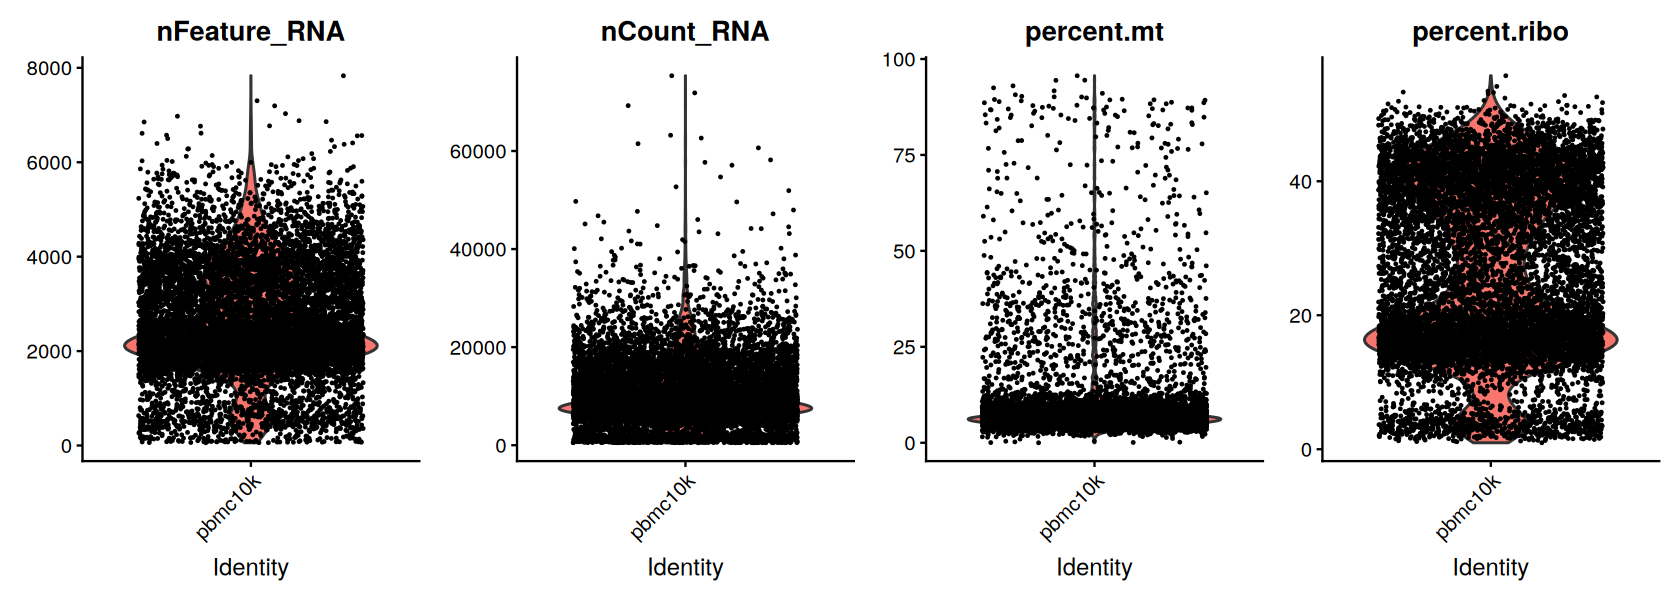

In [9]:
options(repr.plot.width = 14, repr.plot.height = 5)
qc_features <- c("nFeature_RNA", "nCount_RNA", "percent.mt", "percent.ribo")

p <- VlnPlot(pbmc_10k, features = qc_features, ncol = 4, pt.size = 0.1) & NoLegend()
save_plot(p, "01_qc_violin_raw.png", width = 14, height = 5)

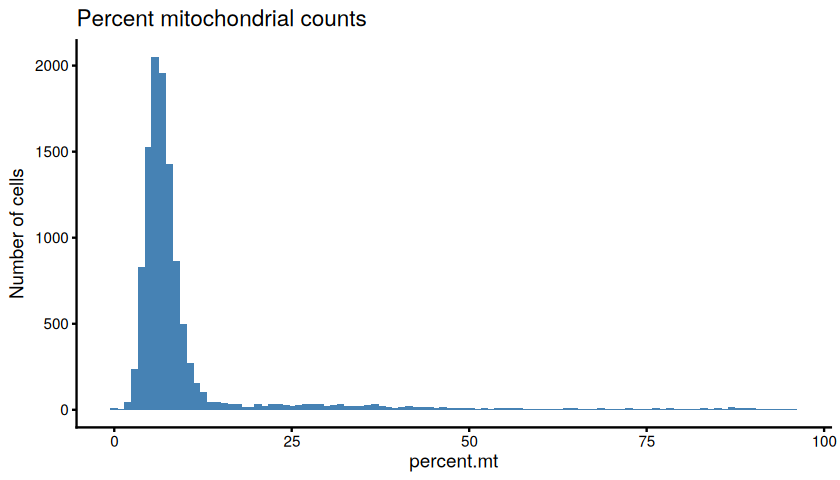

In [10]:
options(repr.plot.width = 7, repr.plot.height = 4)
p <- ggplot(pbmc_10k@meta.data, aes(x = percent.mt)) +
  geom_histogram(bins = 100, fill = "steelblue") +
  labs(title = "Percent mitochondrial counts", x = "percent.mt", y = "Number of cells") +
  theme_classic()
save_plot(p, "02_hist_percent_mt.png", width = 7, height = 4)

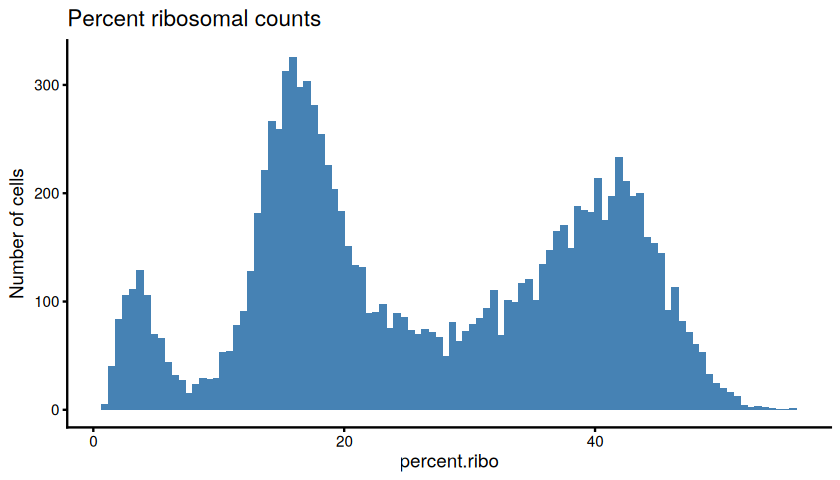

In [11]:
options(repr.plot.width = 7, repr.plot.height = 4)
p <- ggplot(pbmc_10k@meta.data, aes(x = percent.ribo)) +
  geom_histogram(bins = 100, fill = "steelblue") +
  labs(title = "Percent ribosomal counts", x = "percent.ribo", y = "Number of cells") +
  theme_classic()
save_plot(p, "03_hist_percent_ribo.png", width = 7, height = 4)

In [12]:
first_10_genes <- head(rownames(pbmc_10k)[!grepl("^(MT-|RPL|RPS)", rownames(pbmc_10k))], 10)
first_10_genes

[1] "MIR1302-2HG" "FAM138A"     "OR4F5"       "AL627309.1"  "AL627309.3" 
 [6] "AL627309.2"  "AL627309.5"  "AL627309.4"  "AP006222.2"  "AL732372.1"

#### B: QC metrics

In [13]:
pbmc_10k
colnames(pbmc_10k@meta.data)          # cell-level metrics (Scanpy: adata.obs)
colnames(pbmc_10k[["RNA"]][[]])       # gene-level metrics (Scanpy: adata.var)

An object of class Seurat 
36601 features across 10985 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

[1] "orig.ident"        "nCount_RNA"        "nFeature_RNA"     
[4] "percent.mt"        "percent.ribo"      "total_counts_mt"  
[7] "total_counts_ribo"

[1] "gene_ids"              "feature_types"         "mt"                   
[4] "ribo"                  "n_cells_by_counts"     "mean_counts"          
[7] "total_counts"          "pct_dropout_by_counts"

##### B1:

Typical QC metrics like percent mitochondrial reads and number of genes per cell are not hard-fixed thresholds. Ideally, the QC metrics are dataset specific. For PBMC data, the violin plots demonstrated MT% ~10% and `nFeature_RNA` (Scanpy: `n_genes_by_counts`) between 0 and 5000 (to maximise number of cells)

In [14]:
# the two QC filters (pandas .between() includes both ends, so >= and <= are used here)
qc1 <- (pbmc_10k$percent.mt < 5) &
       (pbmc_10k$nFeature_RNA >= 500 & pbmc_10k$nFeature_RNA <= 1000)

qc2 <- (pbmc_10k$percent.mt < 10) &
       (pbmc_10k$nFeature_RNA >= 200 & pbmc_10k$nFeature_RNA <= 500)

In [15]:
c(qc1 = sum(qc1), qc2 = sum(qc2))

qc1 qc2 
 10  65

There are 49 and 69 cells that pass QC filters mentioned above (Scanpy run).
However, this is too little number from initial 10k cells.

In [16]:
qc_set1 <- (pbmc_10k$percent.mt < 10) &
           (pbmc_10k$nFeature_RNA >= 200 & pbmc_10k$nFeature_RNA <= 2500)
sum(qc_set1)

[1] 4868

We can slightly increase the upper-limit for `nFeature_RNA` as we are losing 50% of data

In [17]:
# recommended QC
qc_recommended <- (pbmc_10k$percent.mt < 10) &
                  (pbmc_10k$nFeature_RNA >= 200 & pbmc_10k$nFeature_RNA <= 4000)
sum(qc_recommended)

[1] 8070

##### Doublet detection (scDblFinder)

A doublet is a droplet that captured two cells. It looks like one cell with about twice the UMIs and genes, and when the two cells are of different types (e.g. a T cell and a monocyte) it can form a fake "intermediate" cluster. The upper `nFeature_RNA` cut-off above only removes the most extreme ones.

`scDblFinder` (Bioconductor; the Scanpy counterpart is `sc.pp.scrublet`) builds artificial doublets by adding up random pairs of cells, then trains a classifier to tell them apart from the real cells. Each cell gets a `scDblFinder.score` (0 to 1) and a `scDblFinder.class` (`singlet` or `doublet`). The expected doublet rate is set from the number of cells (0.8% per 1,000 cells, the rate for a standard 10x chip).

As the scDblFinder guidelines recommend, it runs **before** the QC filter, on every barcode with at least 200 genes. The doublets are then removed together with the recommended QC filter.

SoupX is a different tool: it removes ambient RNA, not doublets, and it needs Cell Ranger's `raw_feature_bc_matrix` (all droplets, including empty ones), which is not part of this dataset.

In [18]:
# WSL2: `bash install.sh` installs everything (conda env seurat_env, kernel "R 4.4.3 (seurat_env)").
# Windows R: run once if the packages are missing:
# install.packages("BiocManager"); BiocManager::install(c("scDblFinder", "SingleCellExperiment"))
# Functions are called with pkg:: so the Bioconductor packages are not attached (they would mask dplyr's desc, first, ...)

# Barcodes with < 200 genes carry too little signal to score; they fail the QC filter anyway
dbl_cells <- colnames(pbmc_10k)[pbmc_10k$nFeature_RNA >= 200]
sce <- SingleCellExperiment::SingleCellExperiment(
  assays = list(counts = LayerData(pbmc_10k, assay = "RNA", layer = "counts")[, dbl_cells])
)

set.seed(198716)
sce <- scDblFinder::scDblFinder(sce, BPPARAM = BiocParallel::SerialParam(RNGseed = 198716))

dbl_calls <- data.frame(
  scDblFinder.class = factor(as.character(sce$scDblFinder.class), levels = c("singlet", "doublet")),
  scDblFinder.score = sce$scDblFinder.score,
  row.names         = colnames(sce)
)
pbmc_10k <- AddMetaData(pbmc_10k, metadata = dbl_calls)   # barcodes with < 200 genes get NA
rm(sce, dbl_calls)

table(scDblFinder.class = pbmc_10k$scDblFinder.class, useNA = "ifany")

Creating ~8708 artificial doublets...

Dimensional reduction

Evaluating kNN...

Training model...

iter=0, 1804 cells excluded from training.

iter=1, 1804 cells excluded from training.

iter=2, 1804 cells excluded from training.

Threshold found:0.277

1194 (11%) doublets called



scDblFinder.class
singlet doublet    <NA> 
   9690    1194     101 

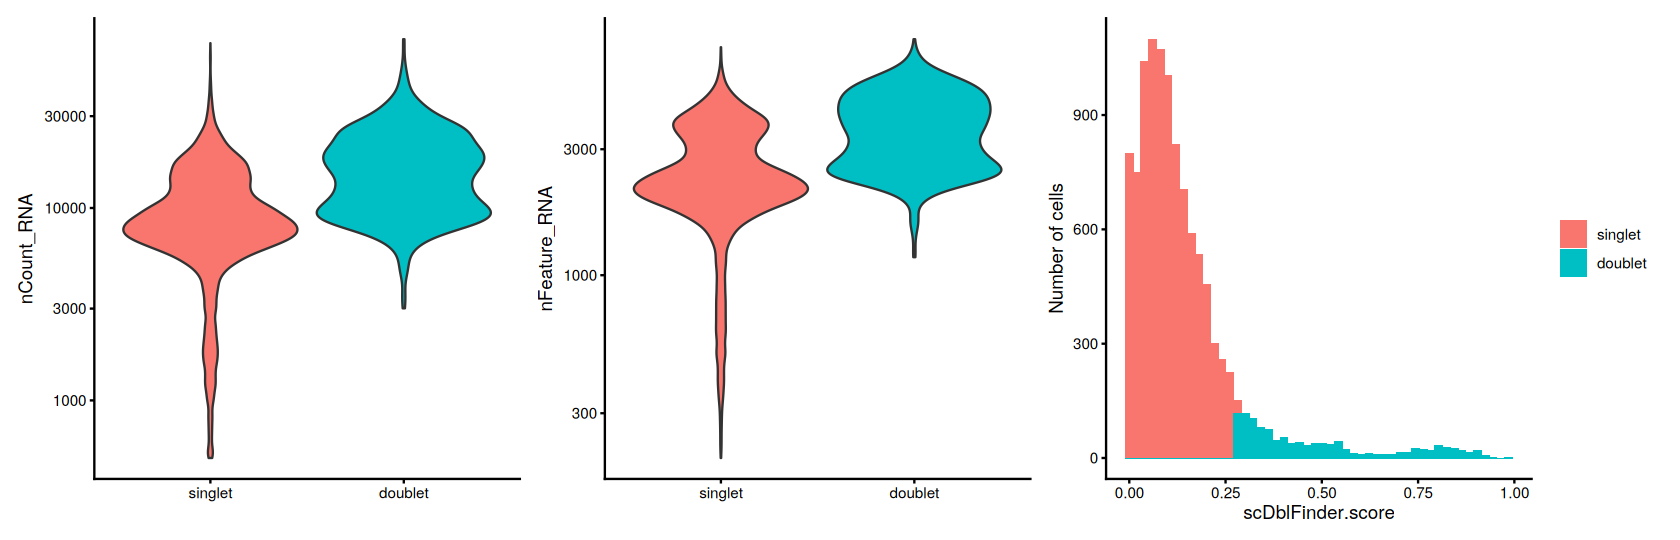

In [19]:
# Doublets should have more UMIs and genes than singlets
dbl_meta <- pbmc_10k@meta.data[!is.na(pbmc_10k$scDblFinder.class), ]

dbl_violin <- function(feature) {
  ggplot(dbl_meta, aes(x = scDblFinder.class, y = .data[[feature]], fill = scDblFinder.class)) +
    geom_violin(scale = "width") +
    scale_y_log10() +
    labs(x = NULL, y = feature) +
    theme_classic() +
    theme(legend.position = "none")
}
p_score <- ggplot(dbl_meta, aes(x = scDblFinder.score, fill = scDblFinder.class)) +
  geom_histogram(bins = 50) +
  labs(x = "scDblFinder.score", y = "Number of cells", fill = NULL) +
  theme_classic()

options(repr.plot.width = 14, repr.plot.height = 4.5)
p <- dbl_violin("nCount_RNA") | dbl_violin("nFeature_RNA") | p_score
save_plot(p, "03b_doublets_scDblFinder.png", width = 14, height = 4.5)

In [20]:
# How many doublets does the recommended QC filter catch on its own?
table(passes_recommended_qc = qc_recommended, scDblFinder.class = pbmc_10k$scDblFinder.class, useNA = "ifany")

# Remove doublets together with the recommended QC filter
# (%in% counts unscored barcodes, < 200 genes, as not passing; they already fail nFeature_RNA >= 200)
qc_recommended <- qc_recommended & (pbmc_10k$scDblFinder.class %in% "singlet")
sum(qc_recommended)

                     scDblFinder.class
passes_recommended_qc singlet doublet <NA>
                FALSE    2335     479  101
                TRUE     7355     715    0

[1] 7355

In [21]:
pbmc_filtered <- subset(pbmc_10k, cells = colnames(pbmc_10k)[qc_recommended])
pbmc_filtered

An object of class Seurat 
36601 features across 7355 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

Initial QC filtered data has 7k cells and 33k genes

Warning message:
“Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead.”


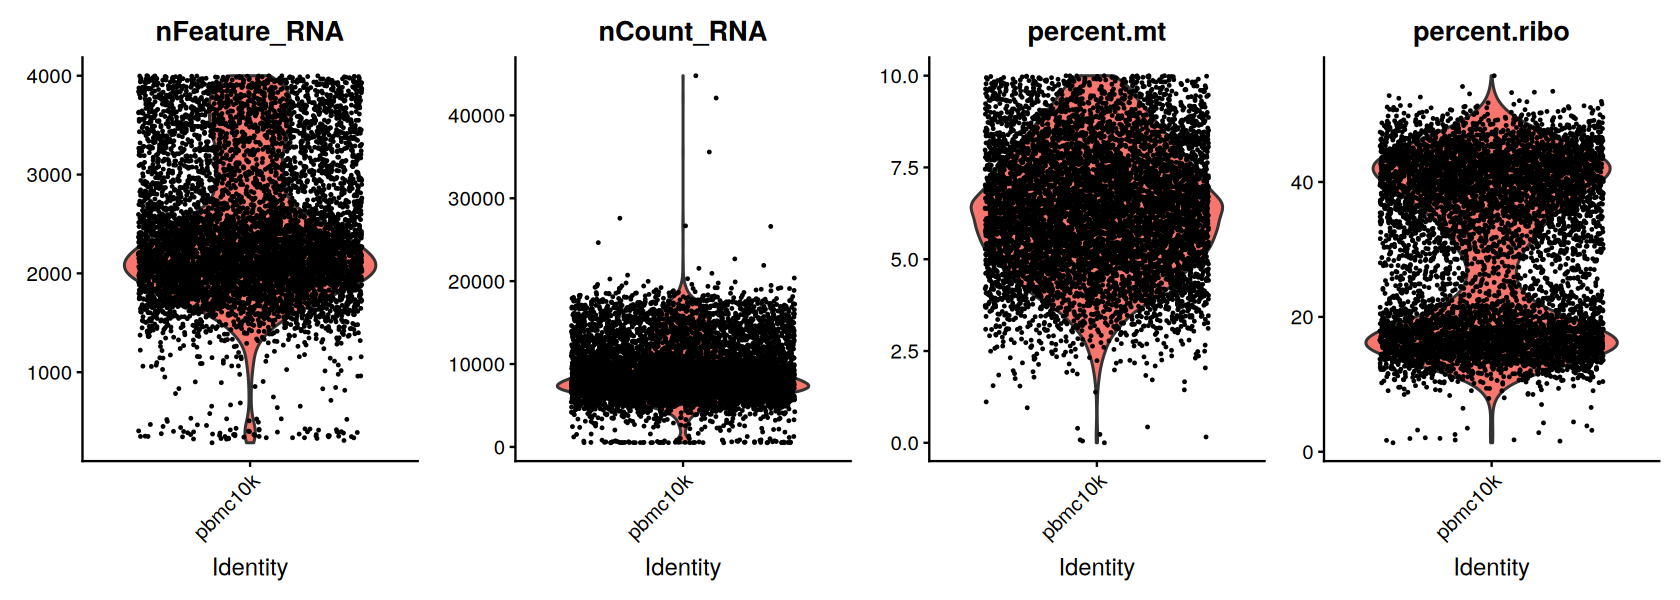

In [22]:
options(repr.plot.width = 14, repr.plot.height = 5)
p <- VlnPlot(pbmc_filtered, features = qc_features, ncol = 4, pt.size = 0.1) & NoLegend()
save_plot(p, "04_qc_violin_filtered.png", width = 14, height = 5)

Interesting to note that `nFeature_RNA` and `percent.ribo` give two major subpopulations. We may later revisit these subpopulations after clustering and check what they may represent

In [23]:
# Scanpy: sc.pp.filter_cells(min_genes=200) then sc.pp.filter_genes(min_cells=5)
filt_counts <- LayerData(pbmc_filtered, assay = "RNA", layer = "counts")
cells_keep  <- colnames(filt_counts)[Matrix::colSums(filt_counts > 0) >= 200]                # cell expresses >= 200 genes
n_cells     <- Matrix::rowSums(filt_counts[, cells_keep, drop = FALSE] > 0)
genes_keep  <- names(n_cells)[n_cells >= 5]                                                  # gene detected in >= 5 cells

pbmc_filtered <- subset(pbmc_filtered, cells = cells_keep, features = genes_keep)
pbmc_filtered$n_genes <- pbmc_filtered$nFeature_RNA
pbmc_filtered[["RNA"]] <- AddMetaData(pbmc_filtered[["RNA"]],
                                      metadata = data.frame(n_cells = n_cells[genes_keep], row.names = genes_keep))
rm(filt_counts)

pbmc_filtered

An object of class Seurat 
19907 features across 7355 samples within 1 assay 
Active assay: RNA (19907 features, 0 variable features)
 1 layer present: counts

Above filtering genes and cells, reduced the number of genes to ~50% of available dataset.  

##### C

Scaling and normalisation

In [24]:
# Scanpy: sc.pp.normalize_total(target_sum=1e4) + sc.pp.log1p  ->  log1p(counts / total_counts * 1e4)
# Seurat writes the result to the "data" layer and keeps the raw counts in the "counts" layer
pbmc_filtered <- NormalizeData(pbmc_filtered, normalization.method = "LogNormalize", scale.factor = 1e4)
pbmc_filtered

Normalizing layer: counts



An object of class Seurat 
19907 features across 7355 samples within 1 assay 
Active assay: RNA (19907 features, 0 variable features)
 2 layers present: counts, data

**HVGs:** Scanpy's `flavor='seurat_v3'` is Seurat's `vst` method. Scanpy warned that it expects raw counts because it was run on log-normalised data. Seurat's `vst` reads the raw `counts` layer automatically, so the HVG list here can differ slightly from the Scanpy run.

In [25]:
pbmc_filtered <- FindVariableFeatures(pbmc_filtered, selection.method = "vst", nfeatures = 1000)
hvg_genes <- VariableFeatures(pbmc_filtered)        # ordered: most variable gene first

hvg_df <- HVFInfo(pbmc_filtered, method = "vst")
hvg_df$gene_name            <- rownames(hvg_df)
hvg_df$highly_variable      <- hvg_df$gene_name %in% hvg_genes
hvg_df$highly_variable_rank <- match(hvg_df$gene_name, hvg_genes)
hvg_df <- hvg_df[hvg_df$highly_variable, ]          # keep only the 1000 HVGs (genome order)

write.csv(hvg_df, file.path(table_dir, "pbmc10k_hvg_1000.csv"), row.names = FALSE)
head(hvg_df)

Finding variable features for layer counts



,mean,variance,variance.expected,variance.standardized,gene_name,highly_variable,highly_variable_rank
,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<lgl>,<int>
HES4,0.195785180,0.996745899,0.240434370,4.145605,HES4,TRUE,119
ISG15,2.320190347,29.358573801,6.317186251,4.502110,ISG15,TRUE,102
TNFRSF18,0.075866757,0.186791726,0.090268663,2.069287,TNFRSF18,TRUE,445
TNFRSF4,0.107002039,0.331899564,0.127186676,2.609547,TNFRSF4,TRUE,285
AJAP1,0.002447315,0.004617344,0.002694873,1.713381,AJAP1,TRUE,712
RBP7,0.655472468,2.542149474,1.002906064,2.534783,RBP7,TRUE,304


In [26]:
pbmc_filtered

An object of class Seurat 
19907 features across 7355 samples within 1 assay 
Active assay: RNA (19907 features, 1000 variable features)
 2 layers present: counts, data

In [27]:
head(hvg_df)

,mean,variance,variance.expected,variance.standardized,gene_name,highly_variable,highly_variable_rank
,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<lgl>,<int>
HES4,0.195785180,0.996745899,0.240434370,4.145605,HES4,TRUE,119
ISG15,2.320190347,29.358573801,6.317186251,4.502110,ISG15,TRUE,102
TNFRSF18,0.075866757,0.186791726,0.090268663,2.069287,TNFRSF18,TRUE,445
TNFRSF4,0.107002039,0.331899564,0.127186676,2.609547,TNFRSF4,TRUE,285
AJAP1,0.002447315,0.004617344,0.002694873,1.713381,AJAP1,TRUE,712
RBP7,0.655472468,2.542149474,1.002906064,2.534783,RBP7,TRUE,304


In [28]:
top10_hvgs <- hvg_df$gene_name[order(hvg_df$highly_variable_rank)][1:10]

In [29]:
top10_hvgs

[1] "IGLC1"  "IGLC3"  "CXCL10" "PTGDS"  "CDKN1C" "GNLY"   "GZMB"   "S100A9"
 [9] "LILRA4" "S100A8"

When using repel, set xnudge and ynudge to 0 for optimal results



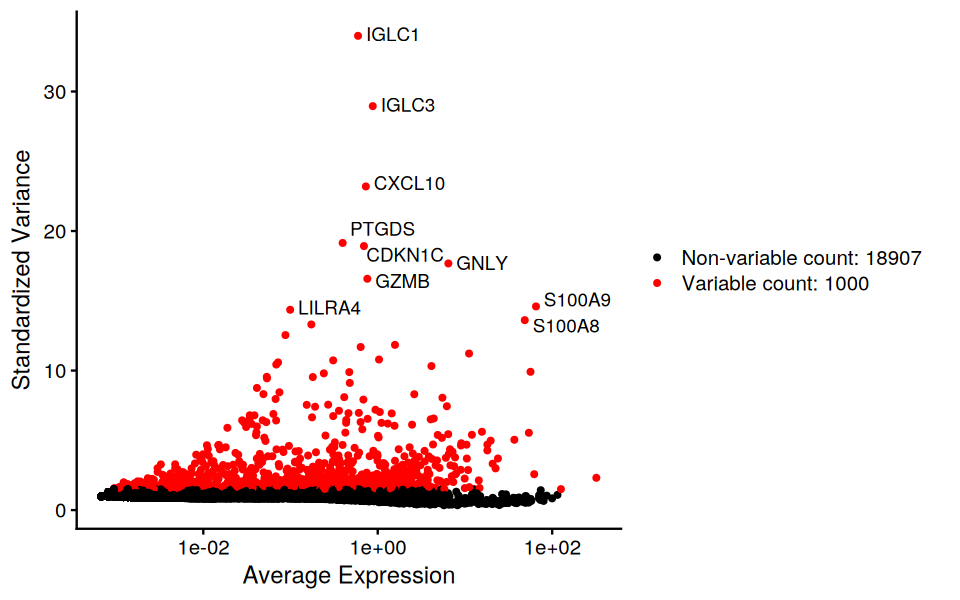

In [30]:
# Seurat's standard HVG plot: mean vs standardised variance, top 10 labelled
options(repr.plot.width = 8, repr.plot.height = 5)
p <- LabelPoints(plot = VariableFeaturePlot(pbmc_filtered), points = top10_hvgs, repel = TRUE)
save_plot(p, "05_variable_features.png", width = 8, height = 5)

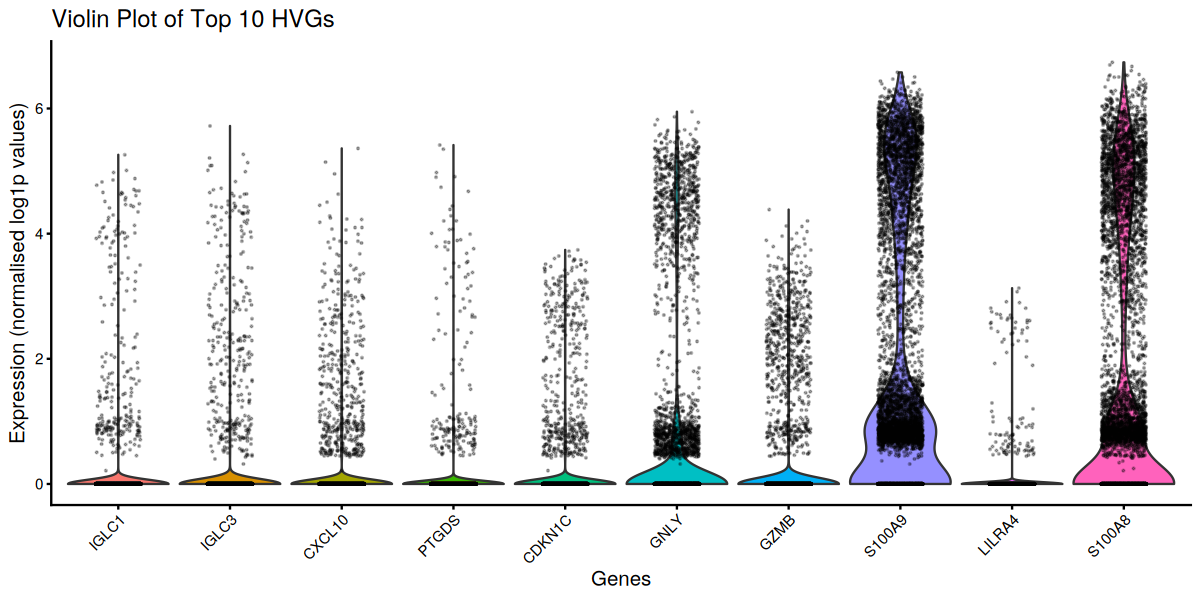

In [31]:
# Violin plot of the top 10 HVGs in one panel (Scanpy: sc.pl.violin(..., multi_panel=False))
expr_mat  <- as.matrix(LayerData(pbmc_filtered, assay = "RNA", layer = "data")[top10_hvgs, ])
expr_long <- data.frame(
  gene       = factor(rep(top10_hvgs, times = ncol(expr_mat)), levels = top10_hvgs),
  expression = as.vector(expr_mat)
)

options(repr.plot.width = 10, repr.plot.height = 5)
p <- ggplot(expr_long, aes(x = gene, y = expression, fill = gene)) +
  geom_violin(scale = "width", trim = TRUE) +
  geom_jitter(width = 0.2, size = 0.1, alpha = 0.3) +
  labs(x = "Genes", y = "Expression (normalised log1p values)", title = "Violin Plot of Top 10 HVGs") +
  theme_classic() +
  theme(axis.text.x  = element_text(angle = 45, hjust = 1),
        axis.title   = element_text(size = 12),
        plot.title   = element_text(size = 14),
        legend.position = "none")
save_plot(p, "06_violin_top10_hvgs.png", width = 10, height = 5)

In [32]:
# Scanpy: adata_hvg = adata_filtered[:, hvg_df['gene_name']].copy()
pbmc_hvg <- subset(pbmc_filtered, features = hvg_df$gene_name)
VariableFeatures(pbmc_hvg) <- hvg_genes
pbmc_hvg

An object of class Seurat 
1000 features across 7355 samples within 1 assay 
Active assay: RNA (1000 features, 1000 variable features)
 2 layers present: counts, data

In [33]:
all(rownames(pbmc_hvg) %in% hvg_df$gene_name)

[1] TRUE

##### Dimensionality reduction

Scanpy's `sc.pp.pca` only mean-centres each gene (`sc.pp.scale` was not run). `ScaleData(do.scale = FALSE)` reproduces that. For the standard Seurat workflow, use `ScaleData()` with its default `do.scale = TRUE`.

In [34]:
pbmc_hvg <- ScaleData(pbmc_hvg, features = hvg_genes, do.center = TRUE, do.scale = FALSE)
pbmc_hvg <- RunPCA(pbmc_hvg, features = hvg_genes, npcs = 50, verbose = FALSE)

Centering data matrix



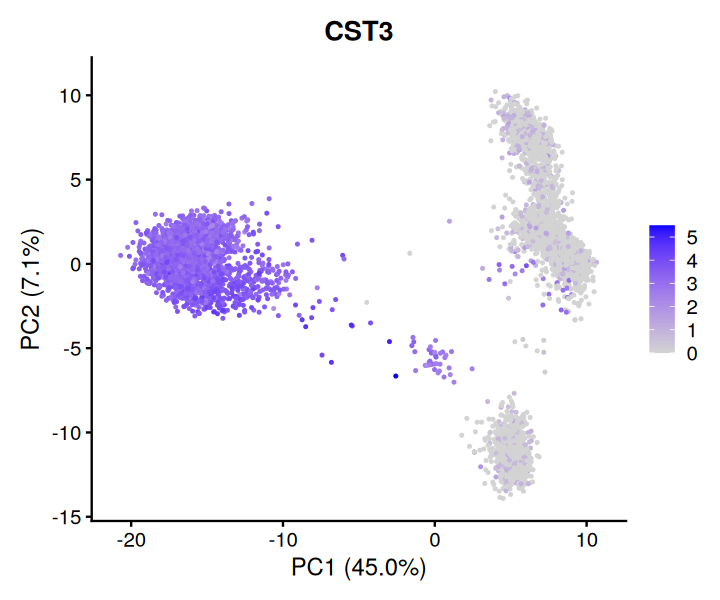

In [35]:
# Scanpy: sc.pl.pca(adata_hvg, annotate_var_explained=True, color="CST3")
var_ratio_hvg <- pca_variance_ratio(pbmc_hvg)

options(repr.plot.width = 6, repr.plot.height = 5)
p <- FeaturePlot(pbmc_hvg, features = "CST3", reduction = "pca", dims = c(1, 2)) +
  labs(x = sprintf("PC1 (%.1f%%)", 100 * var_ratio_hvg$variance_ratio[1]),
       y = sprintf("PC2 (%.1f%%)", 100 * var_ratio_hvg$variance_ratio[2]))
save_plot(p, "07_pca_CST3.png", width = 6, height = 5)

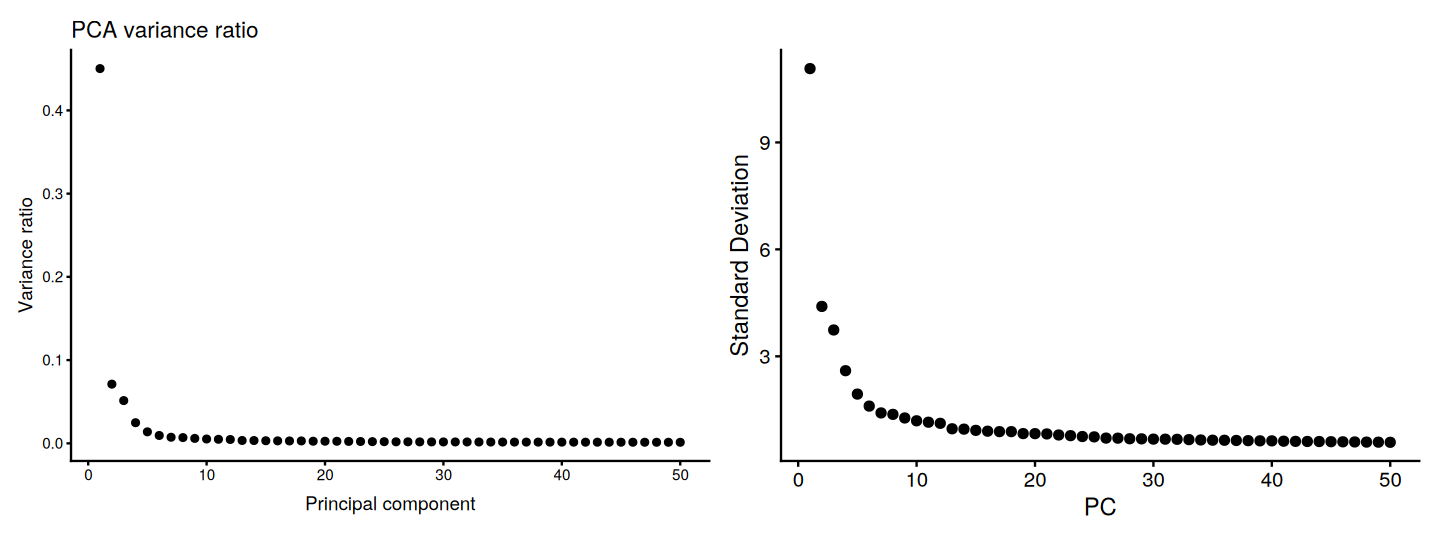

In [36]:
# Scanpy: sc.pl.pca_variance_ratio(n_pcs=50); ElbowPlot is the usual Seurat equivalent (standard deviation per PC)
options(repr.plot.width = 12, repr.plot.height = 4.5)
p <- ggplot(var_ratio_hvg, aes(x = PC, y = variance_ratio)) +
  geom_point() +
  labs(title = "PCA variance ratio", x = "Principal component", y = "Variance ratio") +
  theme_classic()
p <- p | ElbowPlot(pbmc_hvg, ndims = 50)
save_plot(p, "08_pca_variance_ratio.png", width = 12, height = 4.5)

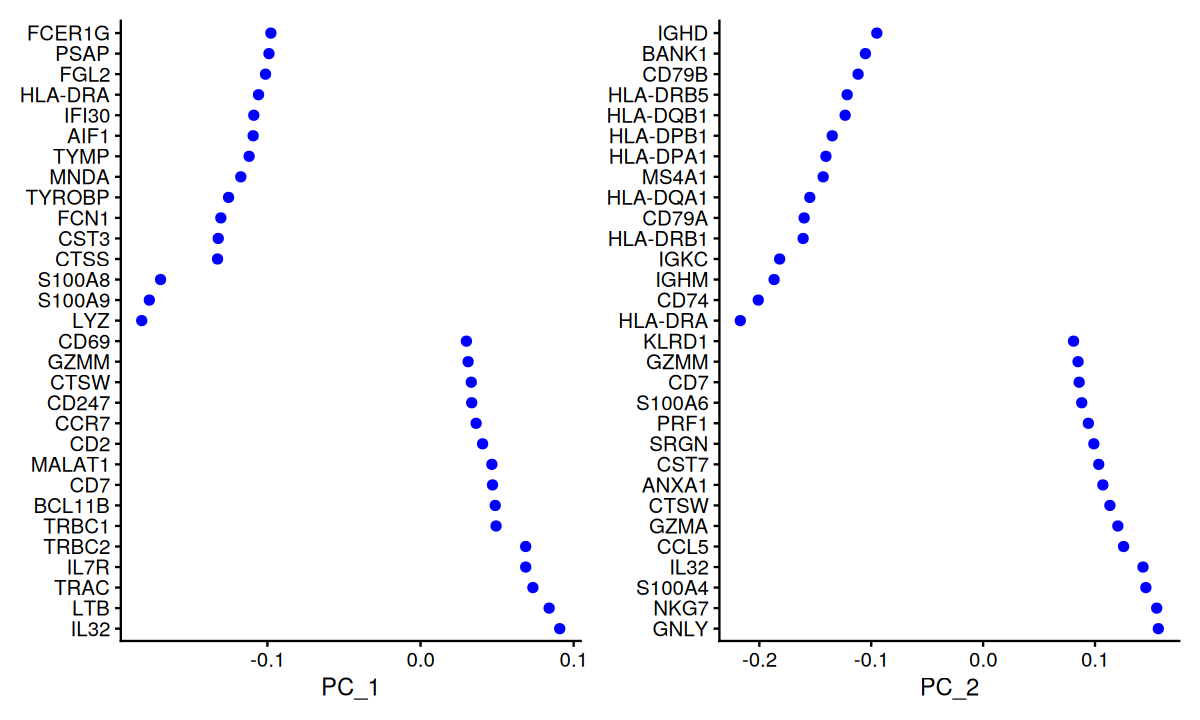

In [37]:
# Scanpy: sc.pl.pca_loadings(components=(1, 2), include_lowest=True)
# balanced = TRUE shows the most positive and the most negative loadings
options(repr.plot.width = 10, repr.plot.height = 6)
p <- VizDimLoadings(pbmc_hvg, dims = 1:2, reduction = "pca", nfeatures = 30, balanced = TRUE)
save_plot(p, "09_pca_loadings_PC1_PC2.png", width = 10, height = 6)

The variance ratio curve flattens after PC7 (elbow). Using the first 7 PCs to create neighbors

In [38]:
# Scanpy: sc.pp.neighbors(n_neighbors=10, n_pcs=7)
pbmc_hvg <- FindNeighbors(pbmc_hvg, reduction = "pca", dims = 1:7, k.param = 10)
pbmc_hvg

Computing nearest neighbor graph

Computing SNN



An object of class Seurat 
1000 features across 7355 samples within 1 assay 
Active assay: RNA (1000 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 1 dimensional reduction calculated: pca

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


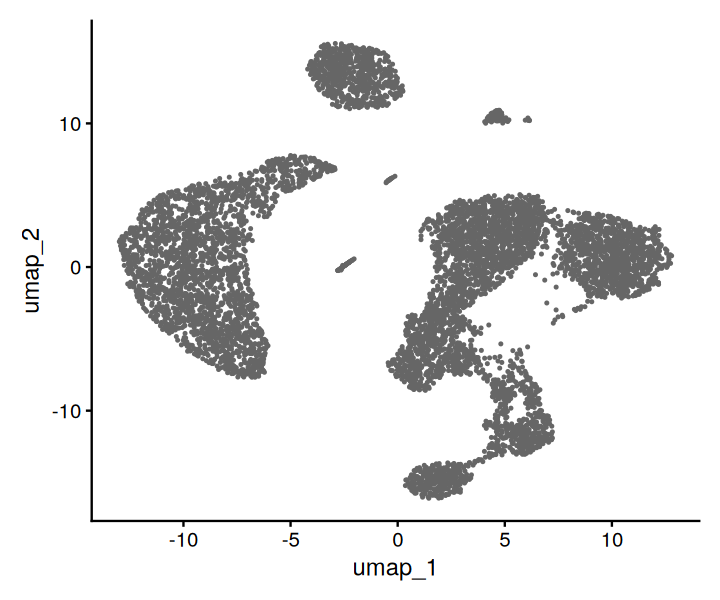

In [39]:
# Scanpy: sc.tl.umap (min_dist = 0.5, neighbours from the graph above)
pbmc_hvg <- RunUMAP(pbmc_hvg, reduction = "pca", dims = 1:7, n.neighbors = 10, min.dist = 0.5,
                    seed.use = 198716, verbose = FALSE)

options(repr.plot.width = 6, repr.plot.height = 5)
p <- DimPlot(pbmc_hvg, reduction = "umap", group.by = "orig.ident", cols = "grey40") + NoLegend() + ggtitle(NULL)
save_plot(p, "10_umap_hvg.png", width = 6, height = 5)

In [40]:
# lets create groups based on QC violin plots and view them in UMAP
mt_cutoff   <- 5
ribo_cutoff <- 25
n_genes_low <- 2000

add_qc_groups <- function(obj) {
  obj$mt_group      <- ifelse(obj$percent.mt   < mt_cutoff,   "low_mt",      "high_mt")
  obj$ribo_group    <- ifelse(obj$percent.ribo < ribo_cutoff, "low_ribo",    "high_ribo")
  obj$n_genes_group <- ifelse(obj$nFeature_RNA < n_genes_low, "low_n_genes", "high_n_genes")
  obj
}

pbmc_hvg <- add_qc_groups(pbmc_hvg)
head(pbmc_hvg@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.ribo,total_counts_mt,total_counts_ribo,scDblFinder.class,scDblFinder.score,n_genes,mt_group,ribo_group,n_genes_group
,<fct>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<int>,<chr>,<chr>,<chr>
AAACCCAGTATCGTAC-1,pbmc10k,1628,749,0.4299754,26.41278,7,430,singlet,0.25000000,749,low_mt,high_ribo,low_n_genes
AAACCCAGTTAGAAAC-1,pbmc10k,17318,3809,5.4913962,16.87262,951,2922,singlet,0.27031151,3809,high_mt,low_ribo,high_n_genes
AAACCCAGTTGCCGAC-1,pbmc10k,6228,2110,6.0533076,11.68915,377,728,singlet,0.06756757,2110,high_mt,low_ribo,high_n_genes
AAACCCATCCATACTT-1,pbmc10k,6689,2372,9.8519958,17.93990,659,1200,singlet,0.11532325,2372,high_mt,low_ribo,high_n_genes
AAACCCATCCATTCGC-1,pbmc10k,11612,3286,6.5277299,12.98657,758,1508,singlet,0.16891892,3286,high_mt,low_ribo,high_n_genes
AAACGAACACCGAATT-1,pbmc10k,10149,2408,3.6161198,44.18169,367,4484,singlet,0.24125807,2408,low_mt,high_ribo,high_n_genes


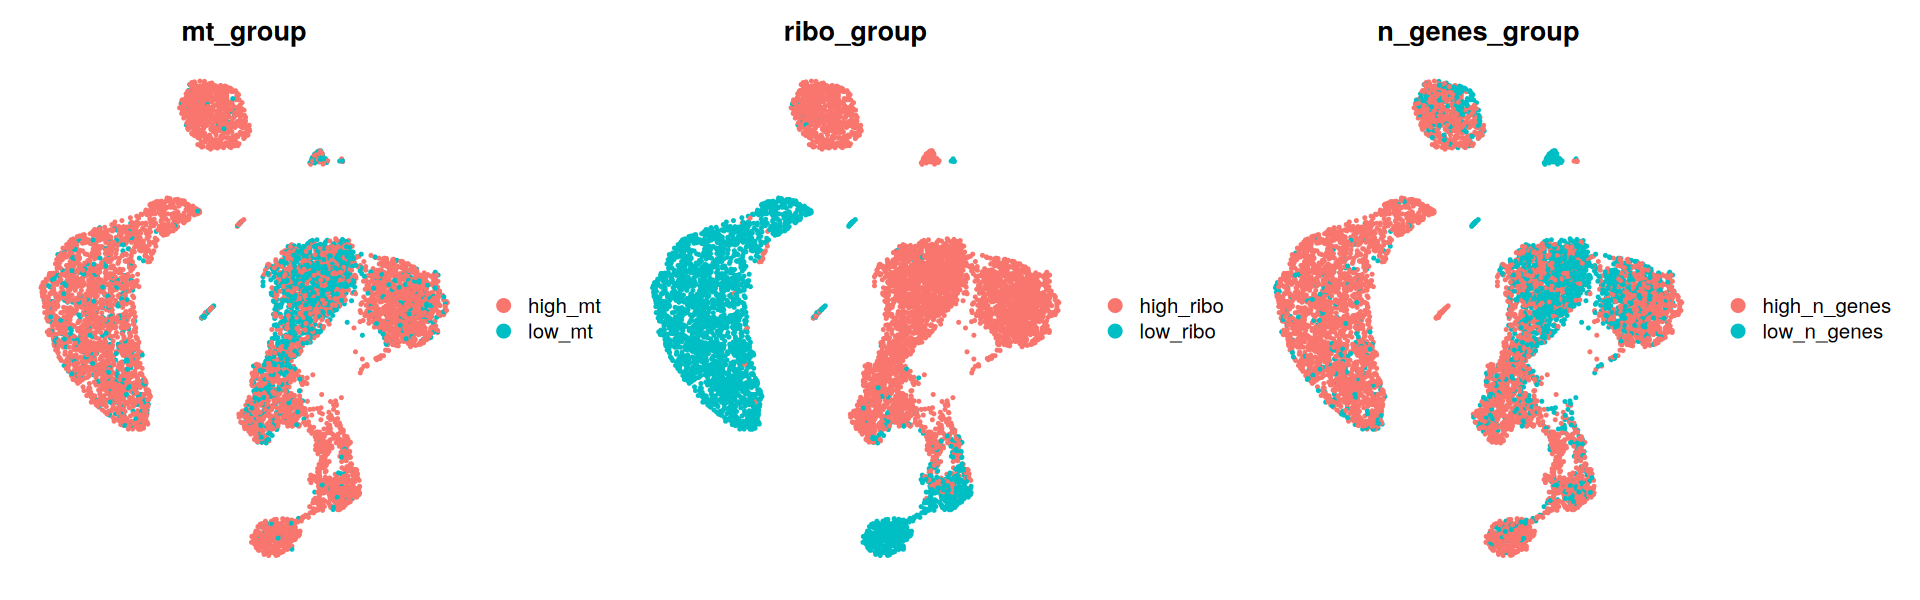

In [41]:
options(repr.plot.width = 16, repr.plot.height = 5)
p <- DimPlot(pbmc_hvg, reduction = "umap", group.by = c("mt_group", "ribo_group", "n_genes_group"), ncol = 3) & NoAxes()
save_plot(p, "11_umap_qc_groups.png", width = 16, height = 5)

Distinct clusters (even before clustering) were found in ribosomal percent and highly expressing cells.

Low ribosomal expressing cells had more expressing genes

In [42]:
saveRDS(pbmc_filtered, file = file.path(results_dir, "pbmc10k_filtered.rds"))

#### E: clustering

In [43]:
pbmc_filtered <- readRDS(file.path(results_dir, "pbmc10k_filtered.rds"))

In [44]:
pbmc_filtered

An object of class Seurat 
19907 features across 7355 samples within 1 assay 
Active assay: RNA (19907 features, 1000 variable features)
 2 layers present: counts, data

In [45]:
# data is already normalised: raw counts are in the "counts" layer and log-normalised values in the
# "data" layer, so no copy is needed (Scanpy: adata.layers['norm_counts'] = adata.X.copy())
Layers(pbmc_filtered)

# run HVG detection, then keep only the HVGs (Scanpy: subset=True)
pbmc_filtered <- FindVariableFeatures(pbmc_filtered, selection.method = "vst", nfeatures = 1000)
hvg_genes     <- VariableFeatures(pbmc_filtered)
pbmc_filtered <- subset(pbmc_filtered, features = hvg_genes)
VariableFeatures(pbmc_filtered) <- hvg_genes

[1] "counts" "data"

Finding variable features for layer counts



Keeping only the 1000 HVGs mirrors the Scanpy notebook, so marker detection and module scores below only see these genes. In a standard Seurat workflow you would keep all genes and let PCA use `VariableFeatures()`.

In [46]:
pbmc_filtered

An object of class Seurat 
1000 features across 7355 samples within 1 assay 
Active assay: RNA (1000 features, 1000 variable features)
 2 layers present: counts, data

In [47]:
pbmc_filtered <- ScaleData(pbmc_filtered, features = hvg_genes, do.center = TRUE, do.scale = FALSE)
pbmc_filtered <- RunPCA(pbmc_filtered, features = hvg_genes, npcs = 50, verbose = FALSE)

Centering data matrix



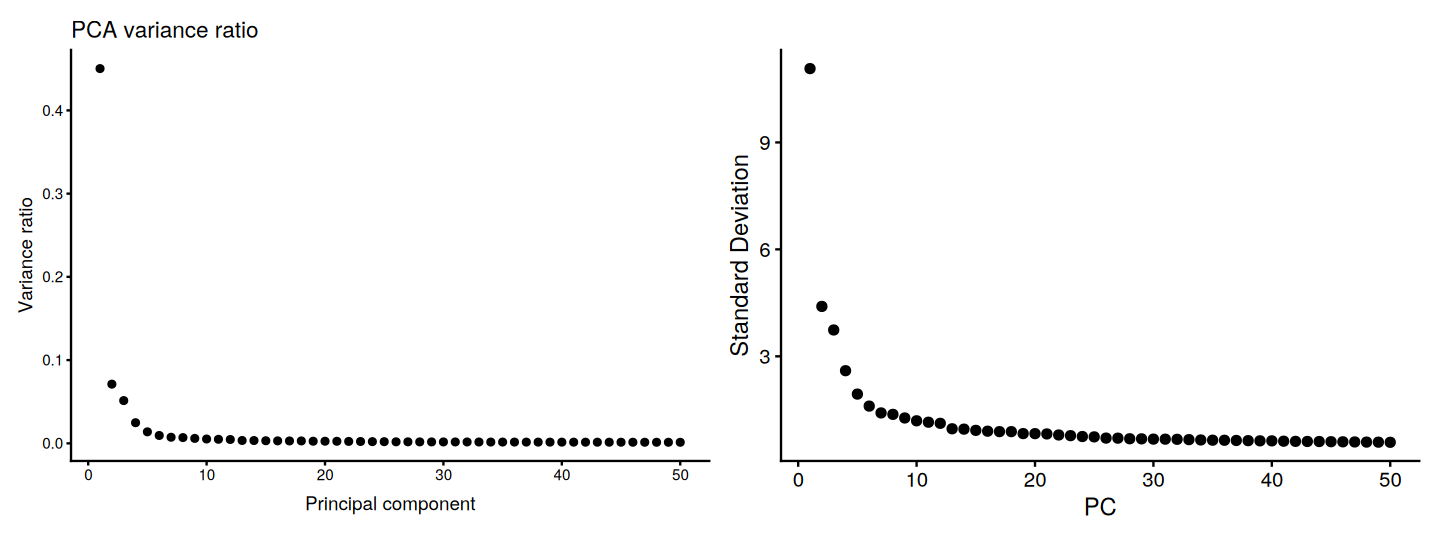

In [48]:
options(repr.plot.width = 12, repr.plot.height = 4.5)
var_ratio <- pca_variance_ratio(pbmc_filtered)
p <- ggplot(var_ratio, aes(x = PC, y = variance_ratio)) +
  geom_point() +
  labs(title = "PCA variance ratio", x = "Principal component", y = "Variance ratio") +
  theme_classic()
p <- p | ElbowPlot(pbmc_filtered, ndims = 50)
save_plot(p, "12_pca_variance_ratio_clustering.png", width = 12, height = 4.5)

In [49]:
pbmc_filtered <- FindNeighbors(pbmc_filtered, reduction = "pca", dims = 1:7, k.param = 10)

Computing nearest neighbor graph

Computing SNN



In [50]:
# Scanpy: sc.tl.louvain(resolution=0.5, random_state=198716, key_added='louvain_0.5')
# algorithm = 1 is the original Louvain algorithm (Seurat clusters the shared nearest neighbour graph)
pbmc_filtered <- FindClusters(pbmc_filtered, resolution = 0.5, algorithm = 1,
                              random.seed = 198716, cluster.name = "louvain_0.5")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 7355
Number of edges: 97200

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9239
Number of communities: 13
Elapsed time: 0 seconds


In [51]:
pbmc_filtered <- RunUMAP(pbmc_filtered, reduction = "pca", dims = 1:7, n.neighbors = 10, min.dist = 0.5,
                         seed.use = 198716, verbose = FALSE)

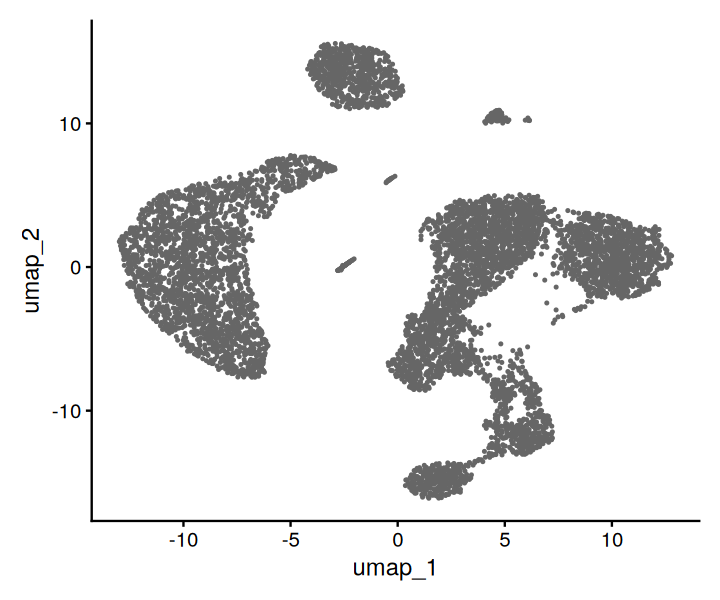

In [52]:
options(repr.plot.width = 6, repr.plot.height = 5)
p <- DimPlot(pbmc_filtered, reduction = "umap", group.by = "orig.ident", cols = "grey40") + NoLegend() + ggtitle(NULL)
save_plot(p, "13_umap_clustering.png", width = 6, height = 5)

In [53]:
pbmc_filtered

An object of class Seurat 
1000 features across 7355 samples within 1 assay 
Active assay: RNA (1000 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

In [54]:
pbmc_filtered <- FindClusters(pbmc_filtered, resolution = 0.7, algorithm = 1,
                              random.seed = 198716, cluster.name = "louvain_0.7")

# FindClusters makes the latest clustering the active identity; switch back to resolution 0.5
Idents(pbmc_filtered) <- "louvain_0.5"

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 7355
Number of edges: 97200

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9038
Number of communities: 15
Elapsed time: 0 seconds


In [55]:
pbmc_filtered
c(clusters_louvain_0.5 = nlevels(pbmc_filtered$louvain_0.5),
  clusters_louvain_0.7 = nlevels(pbmc_filtered$louvain_0.7))

An object of class Seurat 
1000 features across 7355 samples within 1 assay 
Active assay: RNA (1000 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

clusters_louvain_0.5 clusters_louvain_0.7 
                  13                   15

In [56]:
# lets create groups based on QC violin plots and view them in UMAP
# (same cut-offs as above: mt_cutoff = 5, ribo_cutoff = 25, n_genes_low = 2000)
pbmc_filtered <- add_qc_groups(pbmc_filtered)
head(pbmc_filtered@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,percent.ribo,total_counts_mt,total_counts_ribo,scDblFinder.class,scDblFinder.score,n_genes,louvain_0.5,seurat_clusters,louvain_0.7,mt_group,ribo_group,n_genes_group
,<fct>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<int>,<fct>,<fct>,<fct>,<chr>,<chr>,<chr>
AAACCCAGTATCGTAC-1,pbmc10k,1628,749,0.4299754,26.41278,7,430,singlet,0.25000000,749,7,4,4,low_mt,high_ribo,low_n_genes
AAACCCAGTTAGAAAC-1,pbmc10k,17318,3809,5.4913962,16.87262,951,2922,singlet,0.27031151,3809,3,5,5,high_mt,low_ribo,high_n_genes
AAACCCAGTTGCCGAC-1,pbmc10k,6228,2110,6.0533076,11.68915,377,728,singlet,0.06756757,2110,3,5,5,high_mt,low_ribo,high_n_genes
AAACCCATCCATACTT-1,pbmc10k,6689,2372,9.8519958,17.93990,659,1200,singlet,0.11532325,2372,6,6,6,high_mt,low_ribo,high_n_genes
AAACCCATCCATTCGC-1,pbmc10k,11612,3286,6.5277299,12.98657,758,1508,singlet,0.16891892,3286,3,5,5,high_mt,low_ribo,high_n_genes
AAACGAACACCGAATT-1,pbmc10k,10149,2408,3.6161198,44.18169,367,4484,singlet,0.24125807,2408,0,0,0,low_mt,high_ribo,high_n_genes


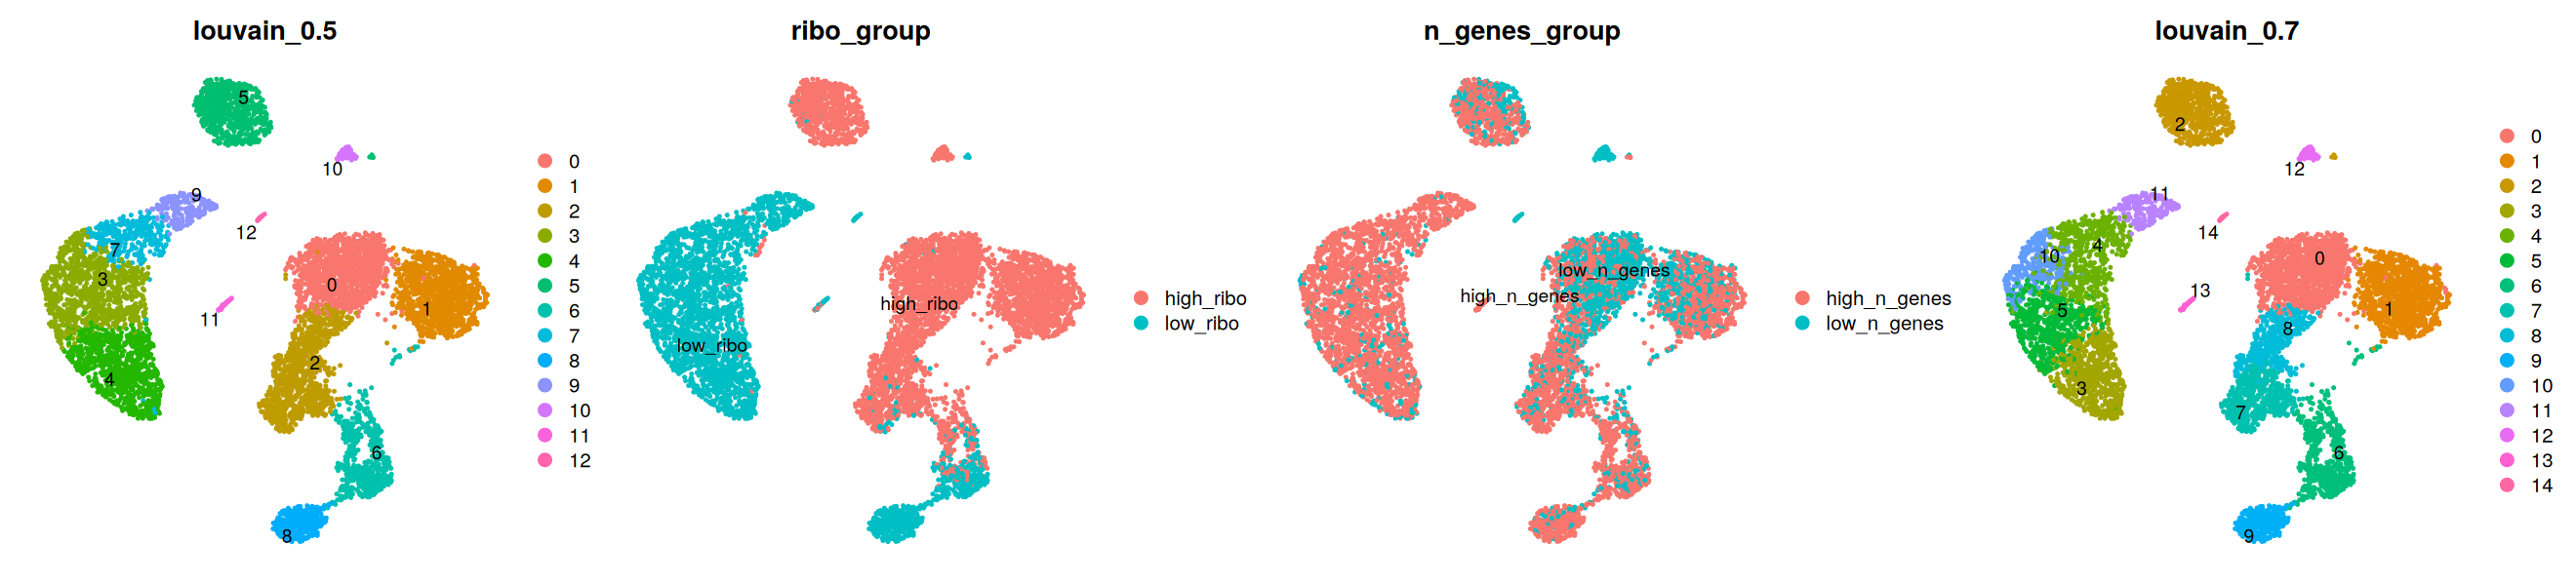

In [57]:
options(repr.plot.width = 22, repr.plot.height = 5)
p <- DimPlot(pbmc_filtered, reduction = "umap",
             group.by = c("louvain_0.5", "ribo_group", "n_genes_group", "louvain_0.7"),
             ncol = 4, label = TRUE, repel = TRUE) & NoAxes()
save_plot(p, "14_umap_clusters_qc_groups.png", width = 22, height = 5)

In the Scanpy run, both the resolutions generated similar number of clusters (N=16). The cluster counts for this Seurat run are printed above.

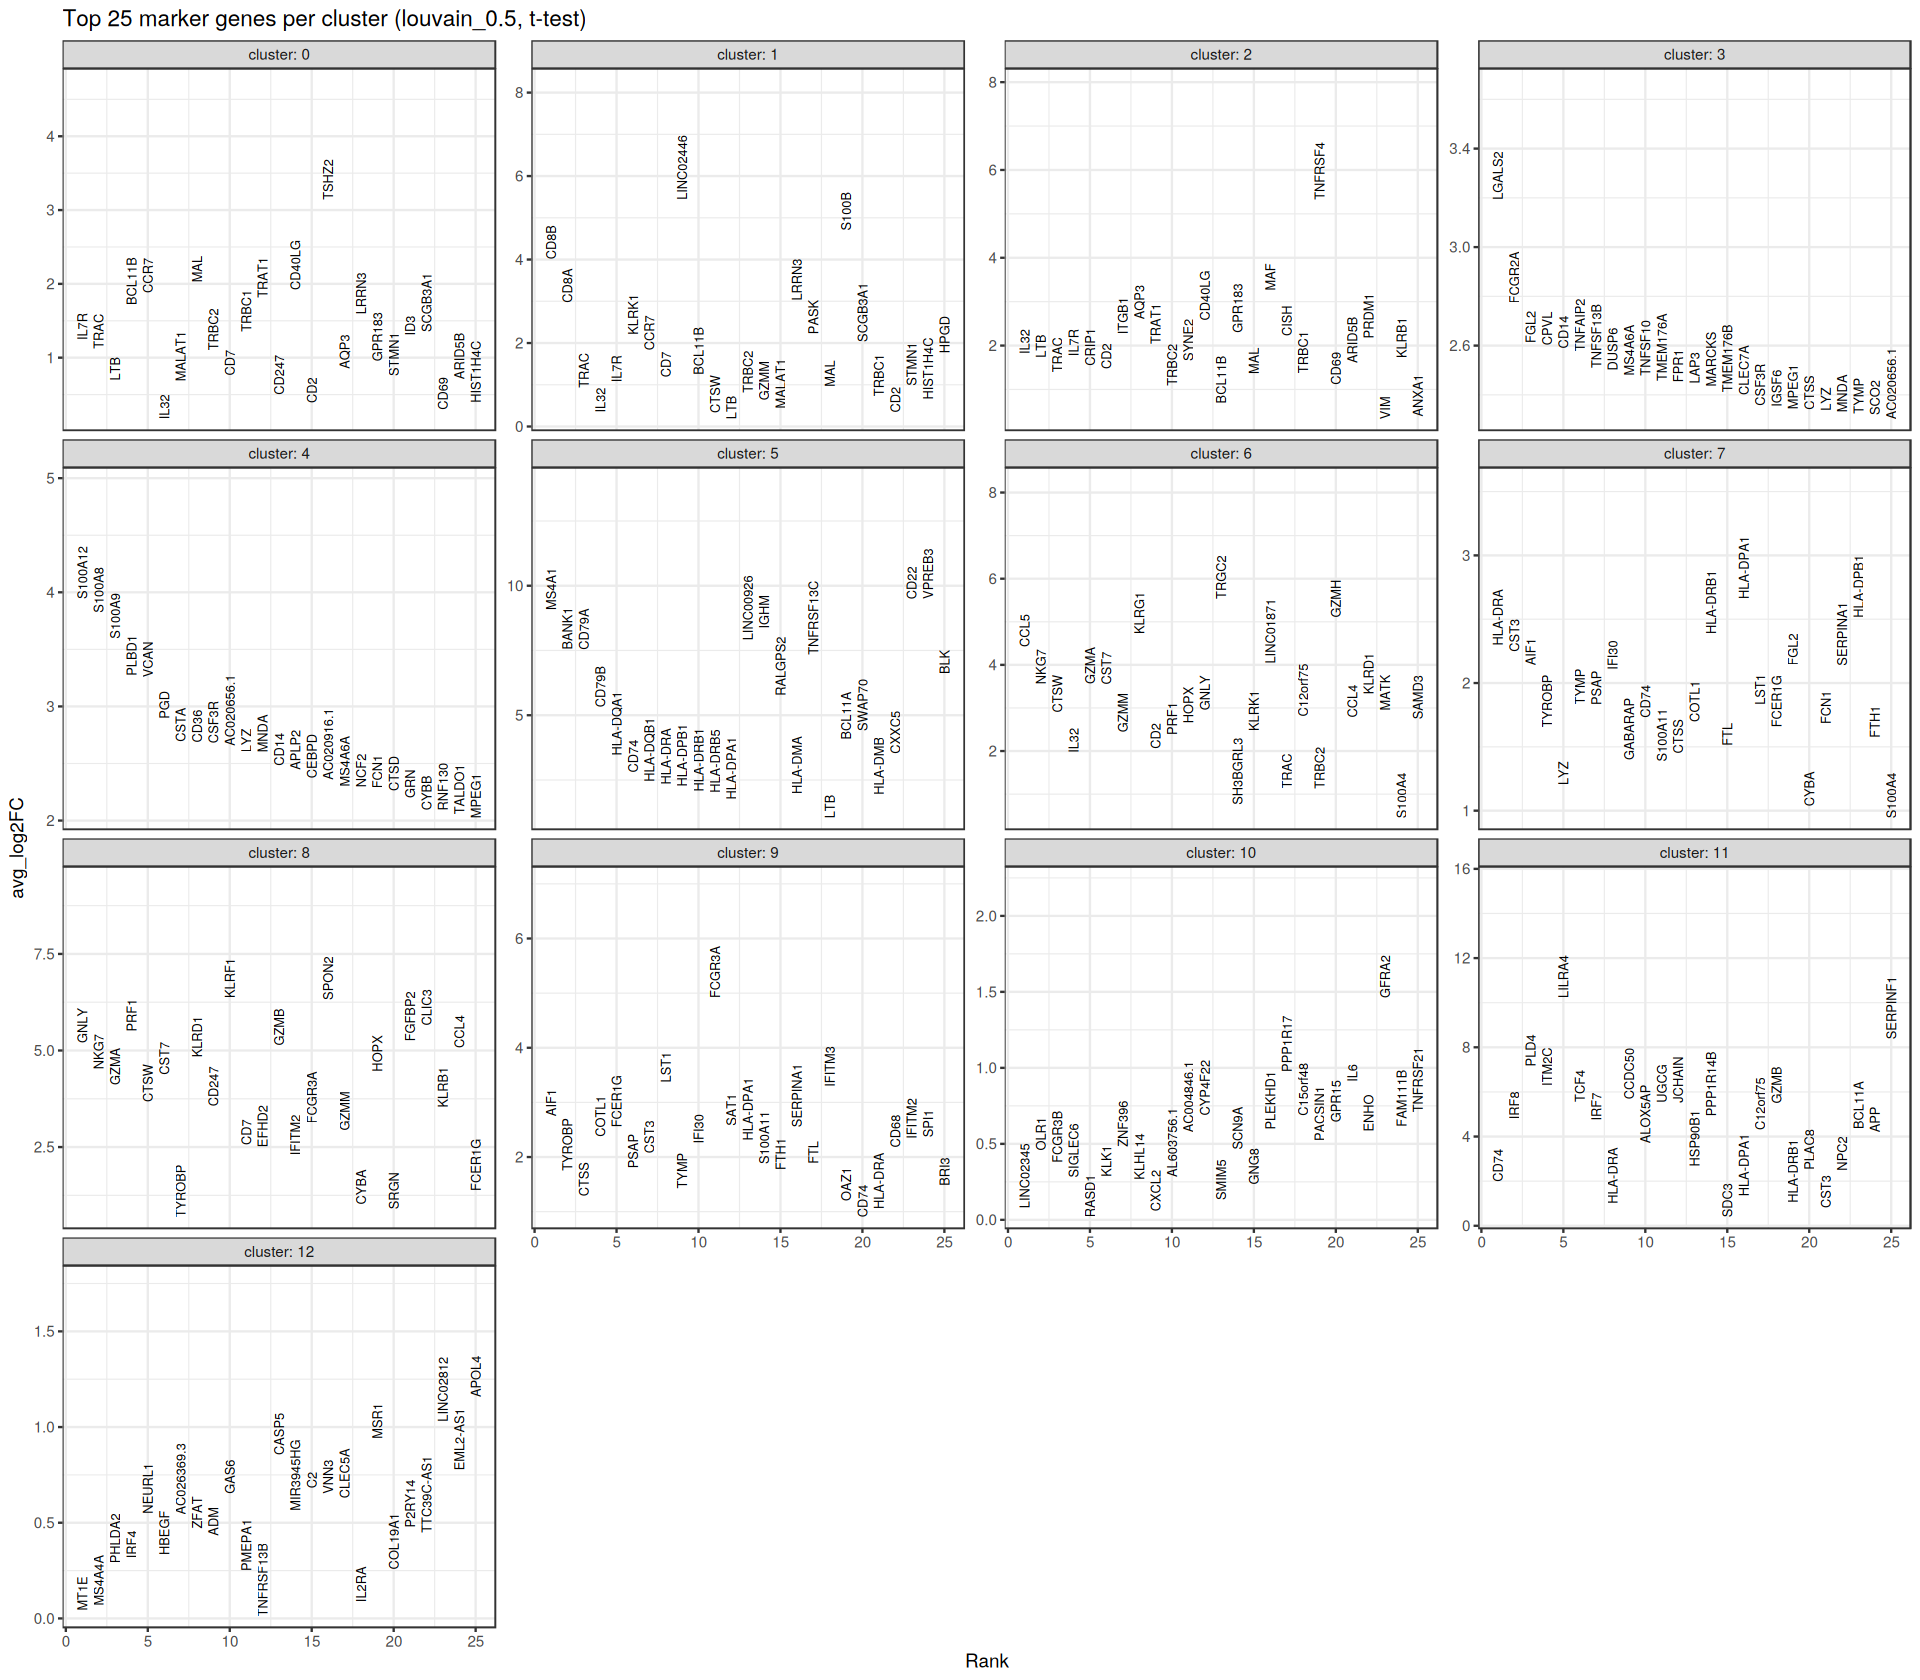

In [58]:
# Scanpy: sc.tl.rank_genes_groups(groupby="louvain_0.5", method="t-test")
# each cluster vs. all other cells; thresholds set to 0 / 1 so every gene is reported, as in Scanpy
markers <- FindAllMarkers(pbmc_filtered, group.by = "louvain_0.5", test.use = "t", only.pos = FALSE,
                          logfc.threshold = 0, min.pct = 0, return.thresh = 1, verbose = FALSE)
write.csv(markers, file.path(table_dir, "pbmc10k_markers_louvain_0.5.csv"), row.names = FALSE)

# Scanpy ranks genes by the t statistic; FindAllMarkers does not return it,
# so up-regulated genes are ranked by p-value and then by fold change
ranked_markers <- markers |>
  filter(avg_log2FC > 0) |>
  group_by(cluster) |>
  arrange(p_val, desc(avg_log2FC), .by_group = TRUE) |>
  mutate(rank = row_number()) |>
  ungroup()

# Scanpy: sc.pl.rank_genes_groups(n_genes=25, sharey=False)
options(repr.plot.width = 16, repr.plot.height = 14)
p <- ggplot(filter(ranked_markers, rank <= 25), aes(x = rank, y = avg_log2FC, label = gene)) +
  geom_text(angle = 90, hjust = 0, size = 2.6) +
  facet_wrap(~ cluster, scales = "free_y", ncol = 4, labeller = label_both) +
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.6))) +
  labs(title = "Top 25 marker genes per cluster (louvain_0.5, t-test)", x = "Rank", y = "avg_log2FC") +
  theme_bw()
save_plot(p, "15_rank_genes_louvain_0.5.png", width = 16, height = 14)

In [59]:
# Get top 5 genes per cluster
top5 <- ranked_markers |>
  filter(rank <= 5) |>
  arrange(cluster, desc(avg_log2FC))
write.csv(top5, file.path(table_dir, "pbmc10k_top5_markers_louvain_0.5.csv"), row.names = FALSE)

top5_genes <- unique(top5$gene)
top5_genes

[1] "CCR7"      "BCL11B"    "IL7R"      "TRAC"      "LTB"       "CD8B"     
 [7] "CD8A"      "IL32"      "CRIP1"     "LGALS2"    "FCGR2A"    "FGL2"     
[13] "CPVL"      "CD14"      "S100A12"   "S100A8"    "S100A9"    "PLBD1"    
[19] "VCAN"      "MS4A1"     "BANK1"     "CD79A"     "CD79B"     "HLA-DQA1" 
[25] "CCL5"      "GZMA"      "NKG7"      "CTSW"      "HLA-DRA"   "CST3"     
[31] "AIF1"      "TYROBP"    "LYZ"       "PRF1"      "GNLY"      "FCER1G"   
[37] "COTL1"     "CTSS"      "OLR1"      "FCGR3B"    "SIGLEC6"   "LINC02345"
[43] "RASD1"     "LILRA4"    "PLD4"      "ITM2C"     "IRF8"      "CD74"     
[49] "NEURL1"    "IRF4"      "PHLDA2"    "MS4A4A"    "MT1E"

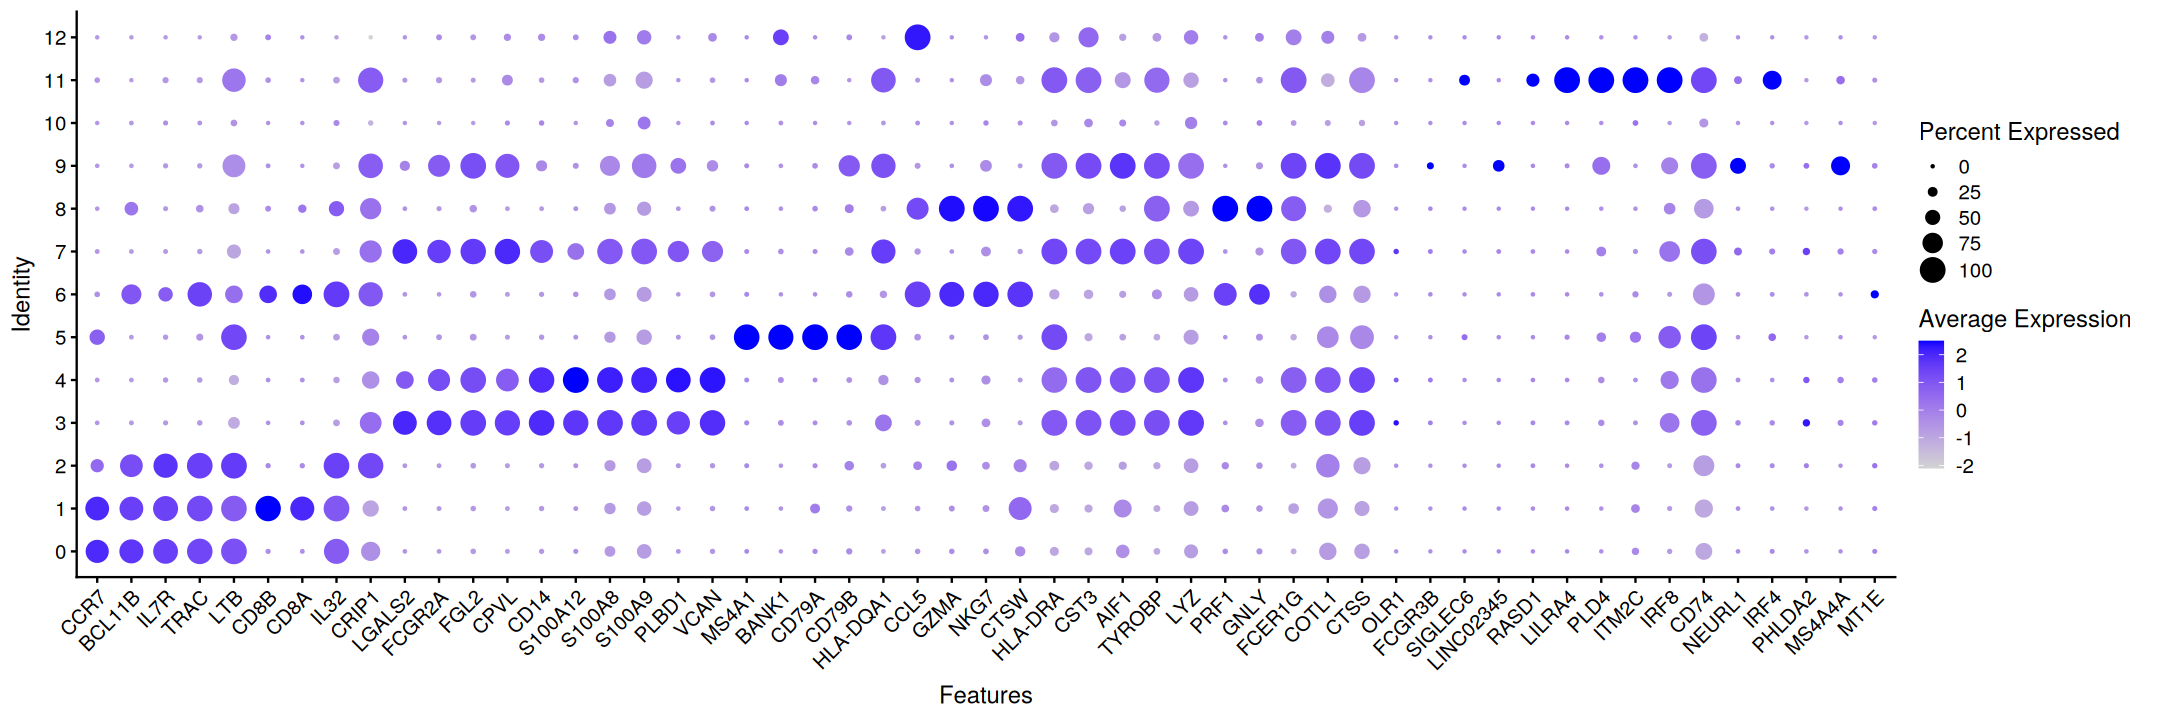

In [60]:
options(repr.plot.width = 18, repr.plot.height = 6)
p <- DotPlot(pbmc_filtered, features = top5_genes, group.by = "louvain_0.5") + RotatedAxis()
save_plot(p, "16_dotplot_top5_markers.png", width = 18, height = 6)

In [61]:
saveRDS(pbmc_filtered, file = file.path(results_dir, "pbmc10k_clustered.rds"))

#### Cell type annotation

Marker genes are from the single-cell best practices guide

In [62]:
marker_genes <- list(
  "CD14+ Mono"          = c("FCN1", "CD14"),
  "CD16+ Mono"          = c("TCF7L2", "FCGR3A", "LYN"),
  "ID2-hi myeloid prog" = c("CD14", "ID2", "VCAN", "S100A9", "CLEC12A", "KLF4", "PLAUR"),
  "cDC1"                = c("CLEC9A", "CADM1"),
  "cDC2"                = c("CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"),     # Note: DMXL2 should be negative
  "Normoblast"          = c("SLC4A1", "SLC25A37", "HBB", "HBA2", "HBA1", "TFRC"),
  "Erythroblast"        = c("MKI67", "HBA1", "HBB"),
  "Proerythroblast"     = c("CDK6", "SYNGR1", "HBM", "GYPA"),                           # Note HBM and GYPA are negative markers
  "NK"                  = c("GNLY", "NKG7", "CD247", "GRIK4", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"),
  "ILC"                 = c("ID2", "PLCG2", "GNLY", "SYNE1"),
  "Lymph prog"          = c("VPREB1", "MME", "EBF1", "SSBP2", "BACH2", "CD79B", "IGHM", "PAX5",
                            "PRKCE", "DNTT", "IGLL1"),
  "Naive CD20+ B"       = c("MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"),
  "B1 B"                = c("MS4A1", "SSPN", "ITGB1", "EPHA4", "COL4A4", "PRDM1", "IRF4", "CD38",
                            "XBP1", "PAX5", "BCL11A", "BLK", "IGHD", "IGHM", "ZNF215"),  # Note IGHD and IGHM are negative markers
  "Transitional B"      = c("MME", "CD38", "CD24", "ACSM3", "MSI2"),
  "Plasma cells"        = c("MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"),
  "Plasmablast"         = c("XBP1", "RF4", "PRDM1", "PAX5"),                            # Note PAX5 is a negative marker ("RF4" kept as in the original list)
  "CD4+ T activated"    = c("CD4", "IL7R", "TRBC2", "ITGB1"),
  "CD4+ T naive"        = c("CD4", "IL7R", "TRBC2", "CCR7"),
  "CD8+ T"              = c("CD8A", "CD8B", "GZMK", "GZMA", "CCL5", "GZMB", "GZMH", "GZMA"),
  "T activation"        = c("CD69", "CD38"),                                            # CD69 much better marker!
  "T naive"             = c("LEF1", "CCR7", "TCF7"),
  "pDC"                 = c("GZMB", "IL3RA", "COBLL1", "TCF4"),
  "G/M prog"            = c("MPO", "BCL2", "KCNQ5", "CSF3R"),
  "HSC"                 = c("NRIP1", "MECOM", "PROM1", "NKAIN2", "CD34"),
  "MK/E prog"           = c("ZNF385D", "ITGA2B", "RYR3", "PLCB1")                       # Note PLCB1 is a negative marker
)

In [63]:
marker_genes_in_data <- lapply(marker_genes, function(markers) markers[markers %in% rownames(pbmc_filtered)])

In [64]:
B_plasma_cts <- c(
  "Naive CD20+ B",
  "B1 B",
  "Transitional B",
  "Plasma cells",
  "Plasmablast"
)

In [65]:
marker_genes_filtered <- lapply(marker_genes, function(genes) genes[genes %in% rownames(pbmc_filtered)])

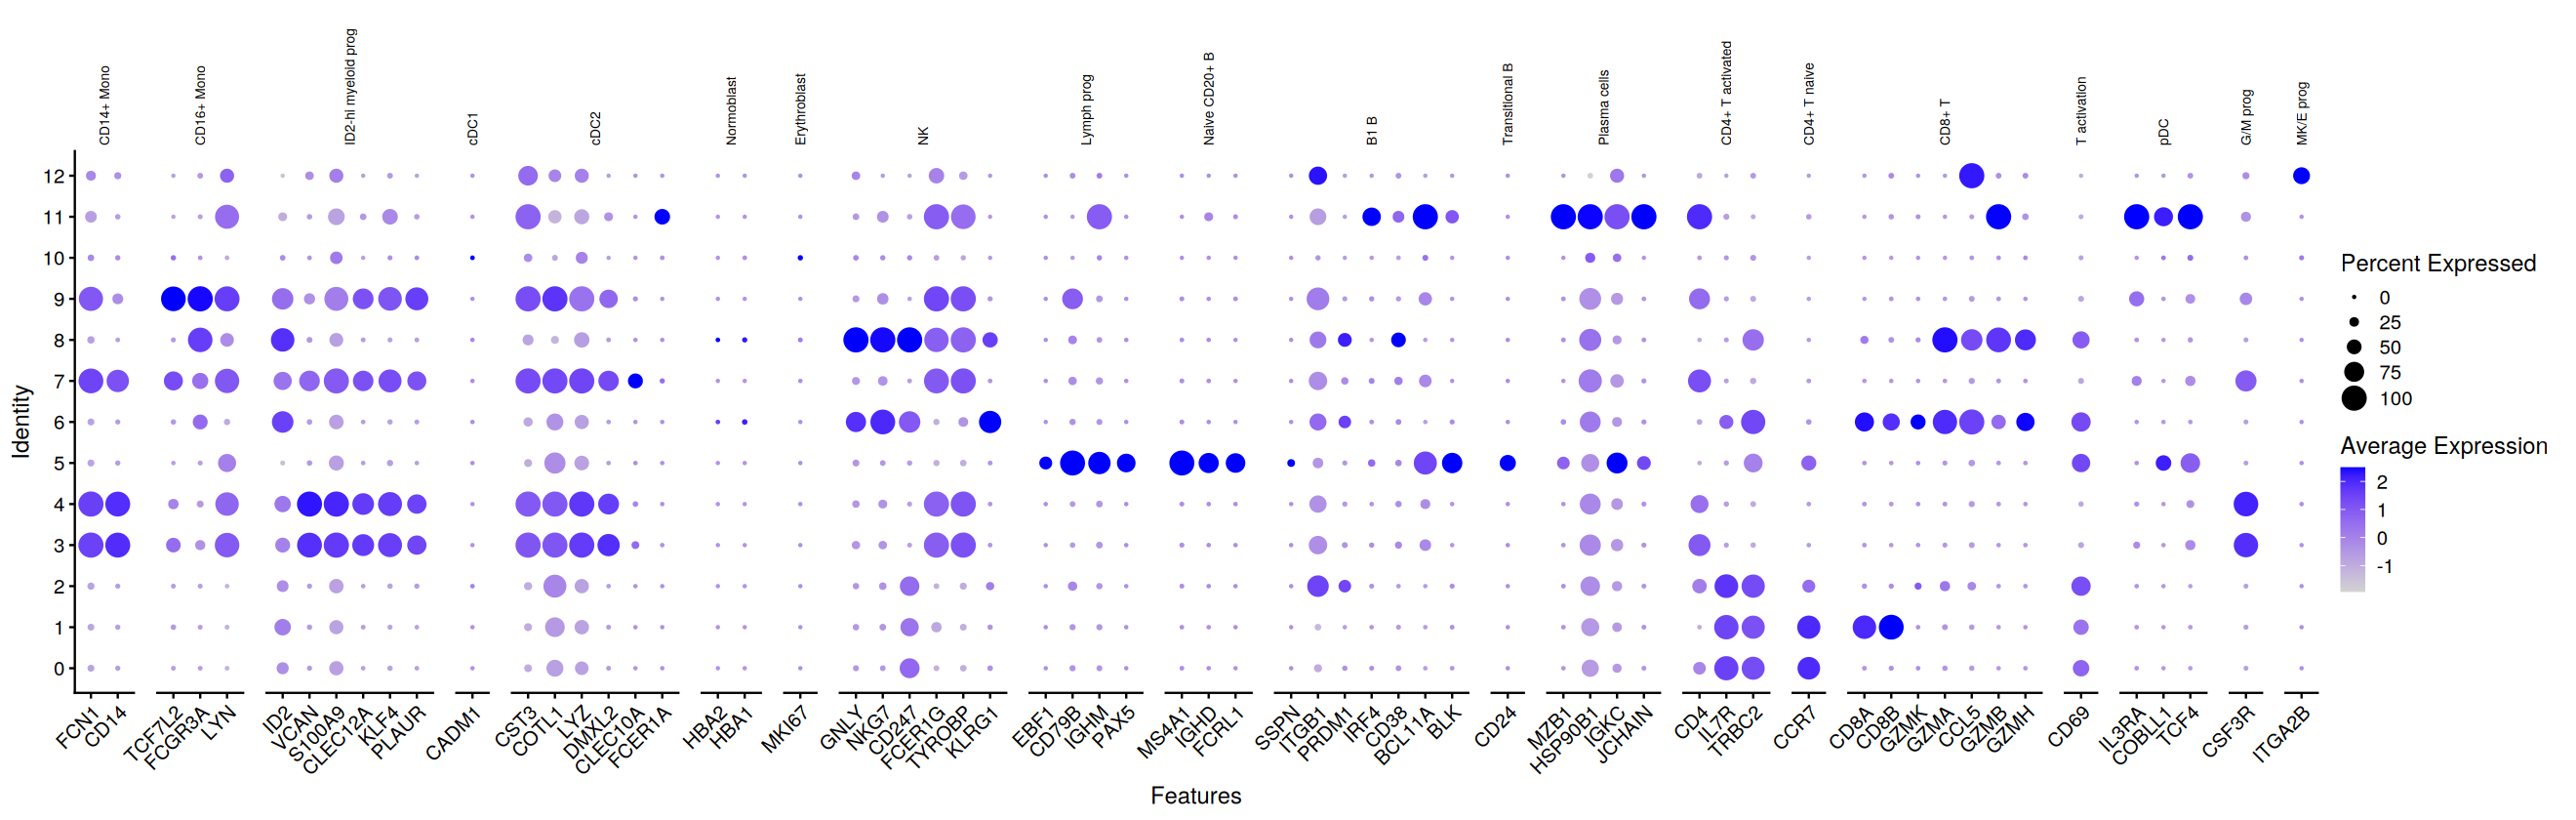

In [66]:
# DotPlot needs each gene once: drop empty groups, and show a gene shared by several cell types under the first one
marker_genes_dotplot <- list()
seen <- character(0)
for (ct in names(marker_genes_filtered)) {
  genes <- setdiff(unique(marker_genes_filtered[[ct]]), seen)
  if (length(genes) > 0) {
    marker_genes_dotplot[[ct]] <- genes
    seen <- c(seen, genes)
  }
}

# scale = TRUE z-scores each gene across clusters
# (Scanpy used standard_scale="var", which rescales each gene to 0-1 across clusters)
options(repr.plot.width = 22, repr.plot.height = 7)
p <- DotPlot(pbmc_filtered, features = marker_genes_dotplot, group.by = "louvain_0.5", scale = TRUE) +
  RotatedAxis() +
  theme(strip.text.x = element_text(angle = 90, hjust = 0, size = 8))
save_plot(p, "17_dotplot_celltype_markers.png", width = 22, height = 7)

In [67]:
# 2. Calculate a "score" for each cell for each marker group
# Scanpy: sc.tl.score_genes -> Seurat: AddModuleScore (mean expression of the genes minus a random
# control set of genes with similar mean expression). Only 1000 genes remain, so each of the 25 expression
# bins holds ~40 genes; ctrl must not exceed that (Scanpy caps it silently, Seurat raises an error).
n_bins    <- 25
ctrl_size <- min(50, floor(nrow(pbmc_filtered) / n_bins) - 1)

for (cell_type in names(marker_genes)) {
  # Check if genes exist in dataset to avoid errors
  valid_genes <- intersect(marker_genes[[cell_type]], rownames(pbmc_filtered))
  if (length(valid_genes) > 0) {
    pbmc_filtered <- AddModuleScore(pbmc_filtered, features = list(valid_genes), name = "module_score",
                                    nbin = n_bins, ctrl = ctrl_size, seed = 198716)
    pbmc_filtered[[cell_type]]   <- pbmc_filtered$module_score1   # rename to the cell type
    pbmc_filtered$module_score1 <- NULL
  }
}

In [68]:
pbmc_filtered
colnames(pbmc_filtered@meta.data)

An object of class Seurat 
1000 features across 7355 samples within 1 assay 
Active assay: RNA (1000 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

[1] "orig.ident"          "nCount_RNA"          "nFeature_RNA"       
 [4] "percent.mt"          "percent.ribo"        "total_counts_mt"    
 [7] "total_counts_ribo"   "scDblFinder.class"   "scDblFinder.score"  
[10] "n_genes"             "louvain_0.5"         "seurat_clusters"    
[13] "louvain_0.7"         "mt_group"            "ribo_group"         
[16] "n_genes_group"       "CD14+ Mono"          "CD16+ Mono"         
[19] "ID2-hi myeloid prog" "cDC1"                "cDC2"               
[22] "Normoblast"          "Erythroblast"        "NK"                 
[25] "ILC"                 "Lymph prog"          "Naive CD20+ B"      
[28] "B1 B"                "Transitional B"      "Plasma cells"       
[31] "Plasmablast"         "CD4+ T activated"    "CD4+ T naive"       
[34] "CD8+ T"              "T activation"        "T naive"            
[37] "pDC"                 "G/M prog"            "MK/E prog"

In [69]:
score_columns <- intersect(names(marker_genes), colnames(pbmc_filtered@meta.data))

# Create a table of mean scores per cluster (rows = clusters, columns = cell types)
cluster_scores <- pbmc_filtered@meta.data |>
  group_by(louvain_0.5) |>
  summarise(across(all_of(score_columns), mean), .groups = "drop")
write.csv(cluster_scores, file.path(table_dir, "pbmc10k_cluster_module_scores.csv"), row.names = FALSE)

score_mat <- as.matrix(cluster_scores[, score_columns])
rownames(score_mat) <- as.character(cluster_scores$louvain_0.5)

# 4. Assign the label with the highest score to each cluster (pandas idxmax)
predicted_labels <- setNames(colnames(score_mat)[max.col(score_mat, ties.method = "first")], rownames(score_mat))

# 5. Map these predictions back to the Seurat object
pbmc_filtered$predicted_cell_type <- unname(predicted_labels[as.character(pbmc_filtered$louvain_0.5)])
predicted_labels

0                  1                  2                  3 
    "CD4+ T naive"          "T naive" "CD4+ T activated"       "CD14+ Mono" 
                 4                  5                  6                  7 
      "CD14+ Mono"    "Naive CD20+ B"              "ILC"             "cDC2" 
                 8                  9                 10                 11 
             "ILC"       "CD16+ Mono"     "Plasma cells"              "pDC" 
                12 
       "MK/E prog"

In [70]:
sort(table(predicted_cell_type = pbmc_filtered$predicted_cell_type), decreasing = TRUE)

predicted_cell_type
      CD14+ Mono     CD4+ T naive          T naive CD4+ T activated 
            1837             1238             1089              982 
             ILC    Naive CD20+ B             cDC2       CD16+ Mono 
             836              723              325              207 
    Plasma cells              pDC        MK/E prog 
              66               37               15 

In [71]:
pbmc_filtered

An object of class Seurat 
1000 features across 7355 samples within 1 assay 
Active assay: RNA (1000 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

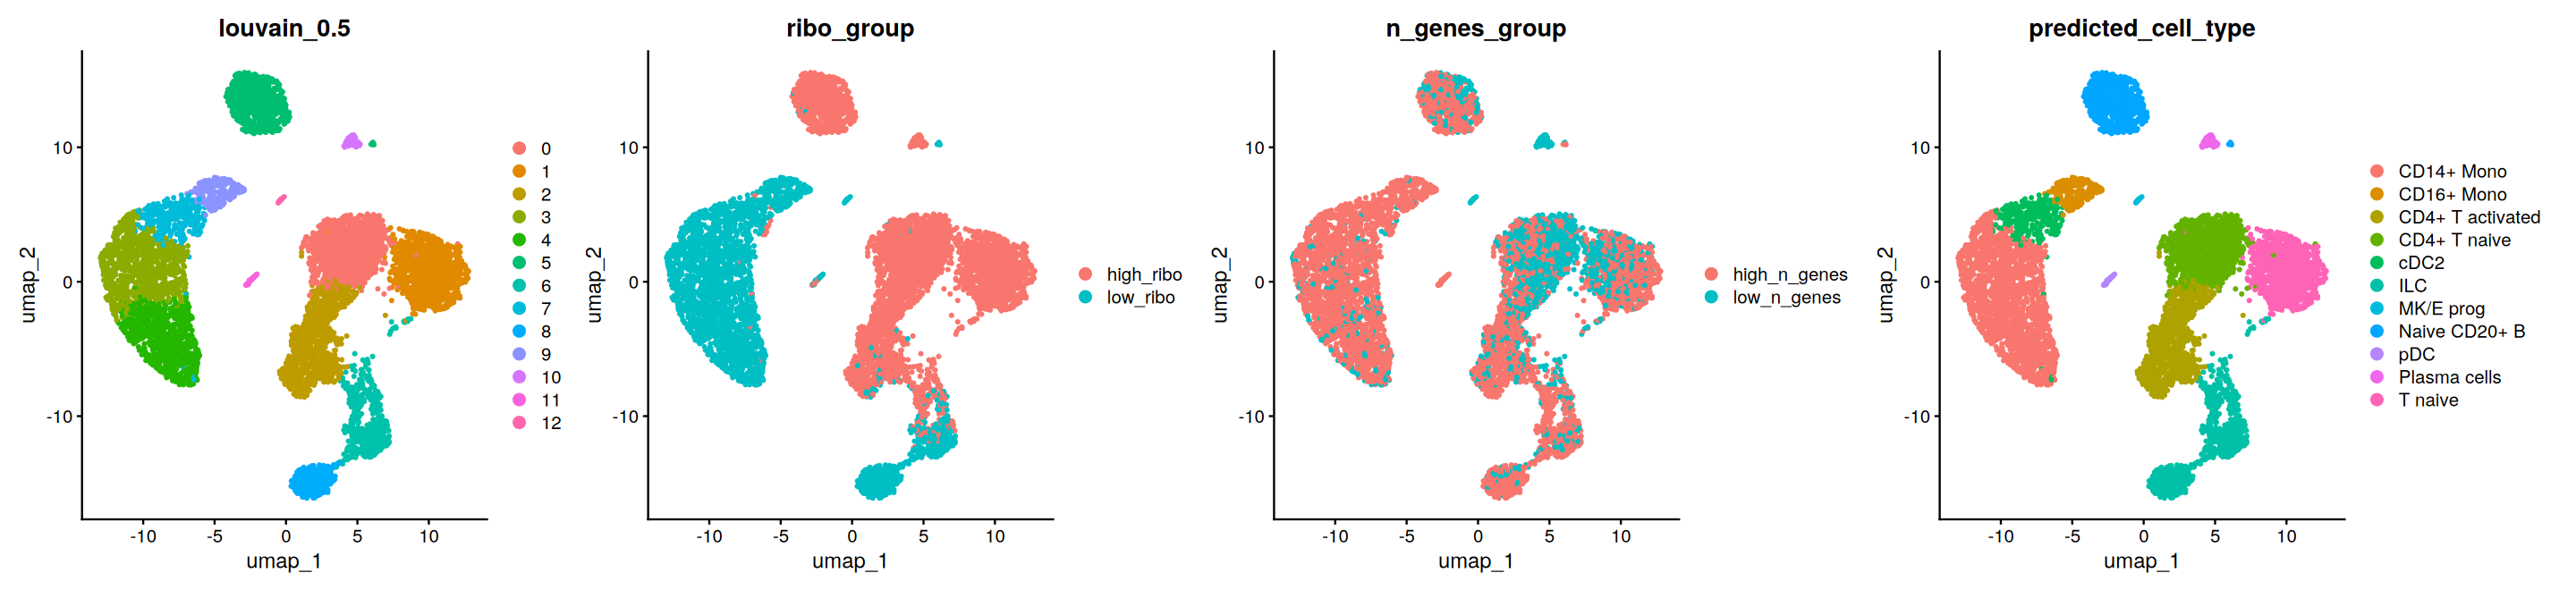

In [72]:
options(repr.plot.width = 24, repr.plot.height = 5.5)
p <- DimPlot(pbmc_filtered, reduction = "umap",
             group.by = c("louvain_0.5", "ribo_group", "n_genes_group", "predicted_cell_type"),
             ncol = 4, pt.size = 0.5)
save_plot(p, "18_umap_predicted_cell_type.png", width = 24, height = 5.5)

In [73]:
ct_vs_ribo <- table(predicted_cell_type = pbmc_filtered$predicted_cell_type,
                    ribo_group          = pbmc_filtered$ribo_group)
write.csv(as.data.frame.matrix(ct_vs_ribo), file.path(table_dir, "pbmc10k_celltype_vs_ribo_group.csv"))
ct_vs_ribo

                   ribo_group
predicted_cell_type high_ribo low_ribo
   CD14+ Mono               3     1834
   CD16+ Mono               0      207
   CD4+ T activated       933       49
   CD4+ T naive          1233        5
   cDC2                    15      310
   ILC                    247      589
   MK/E prog                0       15
   Naive CD20+ B          707       16
   pDC                     19       18
   Plasma cells            66        0
   T naive               1089        0

In [74]:
ct_vs_ngenes <- table(predicted_cell_type = pbmc_filtered$predicted_cell_type,
                      n_genes_group       = pbmc_filtered$n_genes_group)
write.csv(as.data.frame.matrix(ct_vs_ngenes), file.path(table_dir, "pbmc10k_celltype_vs_n_genes_group.csv"))
ct_vs_ngenes

                   n_genes_group
predicted_cell_type high_n_genes low_n_genes
   CD14+ Mono               1676         161
   CD16+ Mono                204           3
   CD4+ T activated          709         273
   CD4+ T naive              481         757
   cDC2                      307          18
   ILC                       663         173
   MK/E prog                   0          15
   Naive CD20+ B             499         224
   pDC                        37           0
   Plasma cells                1          65
   T naive                   703         386

Here is the breakdown of why these patterns exist in healthy biology:

1. Why Lymphocytes are "High Ribo / Low Genes"

Naive T cells and B cells are essentially in "standby mode" (G0 phase).

Biology: They have very little cytoplasm compared to their nucleus (high nuclear-to-cytoplasmic ratio). They aren't actively fighting an infection yet, so they don't need to express a wide variety of effector genes (Low Gene Count).

Why High Ribo? Even though they are resting, they must be ready to translate proteins rapidly the moment they meet an antigen. Therefore, a large chunk of their limited cytoplasmic RNA is dedicated to the protein-making machinery itself (Ribosomes).

The Artifact: Because their total RNA count is low, the ribosomal RNA takes up a larger percentage of the pie.

2. Why Monocytes/DCs are "Low Ribo / High Genes"

Your Monocytes and Dendritic Cells (DCs) are the "scouts" and "trash collectors" of the immune system.

Biology: These are physically larger cells with voluminous cytoplasm. They are constantly phagocytosing (eating) debris, sensing cytokines, and moving through tissue.

Why High Genes? To do these complex tasks, they must transcribe a massive library of receptors, enzymes, and signaling molecules (High Gene Count).

Why Low Ribo? They still have ribosomes, but because they have so much other mRNA floating around (for all those receptors and enzymes), the ribosomal fraction gets "diluted" down to a lower percentage.

In [75]:
saveRDS(pbmc_filtered, file = file.path(results_dir, "pbmc10k_clustered_annotated.rds"))
write.csv(pbmc_filtered@meta.data, file.path(table_dir, "pbmc10k_cell_metadata.csv"))

In [76]:
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /home/sreeram/miniconda3/envs/seurat_env/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Asia/Kolkata
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] future_1.82.0      patchwork_1.3.2    ggplot2_4.0.3      tidyr_1.3.2       
[5] dplyr_1.2.1        Matrix_1.7-6       Seurat_5.5.1       SeuratObject_5.4.0
[9] sp_2.2-3          

loaded via a namespace (and not attached):
  [1] RcppAnnoy_0.0.23            splines_4.4.3             